# Antibiotic trade (BACI 2024): supply risk and register comparison

The single notebook for the trade part of the paper. Every file in `figures/trade/` is written by a `save(...)`
call below; run the notebook top to bottom to regenerate all of them.

**Data.** BACI 2024 bilateral trade for the 4 antibiotic HS-6 lines (294110 penicillins, 294130 tetracyclines,
294150 macrolides, 294190 other antibiotics), pooled. **Weights:** value (thousand USD), volume (tonnes) and
risk-adjusted `str` (systemic-risk pipeline, `Data/sys_risk`). `str` covers imports only, so import exposure,
the fragility map and the shock, which also need exports, come by value and volume only.

**Figure style.** No titles and no definitions in axis labels. A figure that exists once per weight has a small
subtitle naming the weight (`value`, `volume`, `risk-adjusted (str)`).

| Section | Figures written to `figures/trade/` |
|---|---|
| 1. Sourcing similarity (cosine) | `cosine.png` |
| 1b. Herding null | `cosine_null.png` |
| 2. Import exposure | `exposure_value.png`, `exposure_volume.png` |
| 3. Largest supplier | `single_sourcing_value.png`, `single_sourcing_volume.png`, `single_sourcing_str.png` |
| 4. Fragility map | `fragility_value.png`, `fragility_volume.png` |
| 5. China + India shock | `shock_value.png`, `shock_volume.png` |
| 6. Register vs trade - Germany | `register_vs_trade_{scatter,bars}_{str,volume}_{cosine,pearson,spearman}.png` |
| 7. CEP vs trade - EU-27 | `cep_vs_trade_{scatter,bars}_{str,volume}_{cosine,pearson,spearman}.png` |
| 7b. CEP split (Supplementary) | no figure; prints the LaTeX table |
| 8. Exploratory: unit value | no figure |

Main-text figures: `cep_vs_trade_scatter_volume_spearman.png`, `exposure_volume.png`, `fragility_volume.png`,
`shock_volume.png`.

## Setup

In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

ROOT = Path('../..').resolve()
DATA = ROOT / 'data' / 'trade'
FIG = ROOT / 'figures' / 'trade'
FIG.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA / 'baci_2024_antibiotics_bilateral.csv')
raw.head(3)

,year,hs6_code,hs6_description,exporter_baci_code,exporter_name,exporter_iso3,importer_baci_code,importer_name,importer_iso3,value_1000_usd,quantity_tonnes
0,2024,294110,Antibiotics: penicillins and their derivatives...,699,India,IND,4,Afghanistan,AFG,176.684,5.325
1,2024,294110,Antibiotics: penicillins and their derivatives...,156,China,CHN,4,Afghanistan,AFG,9.360,0.300
2,2024,294110,Antibiotics: penicillins and their derivatives...,516,Namibia,NAM,24,Angola,AGO,24.891,0.100


In [2]:
# rename columns and take only data we need 
df = raw[['year', 'exporter_name', 'importer_name', 'value_1000_usd', 'quantity_tonnes']].copy()
df['unit_value'] = df['value_1000_usd'] / df['quantity_tonnes']
df.head(3)

,year,exporter_name,importer_name,value_1000_usd,quantity_tonnes,unit_value
0,2024,India,Afghanistan,176.684,5.325,33.180094
1,2024,China,Afghanistan,9.360,0.300,31.200000
2,2024,Namibia,Angola,24.891,0.100,248.910000


In [3]:
# --- setup: shared constants, EU-27 import shares per weight, paper figure style ---
from pathlib import Path
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import pyarrow.compute as pc
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

HS4  = ['294110', '294130', '294150', '294190']
EU27_ISO = ['AUT','BEL','BGR','HRV','CYP','CZE','DNK','EST','FIN','FRA','DEU','GRC','HUN','IRL',
            'ITA','LVA','LTU','LUX','MLT','NLD','POL','PRT','ROU','SVK','SVN','ESP','SWE']
ISO_NAME = dict(zip(raw.exporter_iso3, raw.exporter_name)) | dict(zip(raw.importer_iso3, raw.importer_name))
NAME_ISO = {name: iso for iso, name in ISO_NAME.items()}

# EU-27 imports: raw BACI (value, volume), and str scaled by each importer's import value in the class
t_eu = raw[raw.importer_iso3.isin(EU27_ISO)].assign(hs=lambda d: d.hs6_code.astype(str))
flt = (pc.field('year') == 2024) & pc.field('importer').isin(EU27_ISO) & pc.field('hs_code').isin(HS4)
st_eu = pd.concat([pq.read_table(str(f), columns=['hs_code', 'importer', 'exporter', 'str'], filters=flt).to_pandas()
                   for f in sorted((DATA / 'sys_risk').glob('*.parquet'))], ignore_index=True)
imp_val = t_eu.groupby(['importer_iso3', 'hs']).value_1000_usd.sum()
st_eu['str_flow'] = st_eu['str'] * imp_val.reindex(list(zip(st_eu.importer, st_eu.hs_code))).values

def eu_shares(w):
    # sourcing shares of each EU-27 importer (rows sum to 1), pooled over the 4 classes
    if w == 'str':
        f = st_eu.groupby(['importer', 'exporter']).str_flow.sum()
    else:
        col = {'value': 'value_1000_usd', 'volume': 'quantity_tonnes'}[w]
        f = t_eu.groupby(['importer_iso3', 'exporter_iso3'])[col].sum()
    m = f.unstack(fill_value=0)
    return m.div(m.sum(axis=1), axis=0)

W_LAB = {'value': 'value', 'volume': 'volume', 'str': 'risk-adjusted (str)'}     # also the figure subtitles
SH_EU = {w: eu_shares(w) for w in W_LAB}
print('EU-27 importers per weight:', {w: len(s) for w, s in SH_EU.items()})

# paper style: no titles, axis names only; a figure that exists per weight gets a small subtitle
EU_C, NONEU_C, ALL_C = '#3a6ea5', '#c0392b', '#8c8c8c'
STYLE = {'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica', 'Arial', 'DejaVu Sans'],
         'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#bbbbbb',
         'xtick.color': '#bbbbbb', 'ytick.color': '#bbbbbb', 'xtick.labelcolor': '#333333',
         'ytick.labelcolor': '#333333', 'axes.labelcolor': '#333333', 'axes.labelsize': 12,
         'xtick.labelsize': 10, 'ytick.labelsize': 10, 'legend.frameon': False,
         'grid.color': '#ebebeb', 'grid.linewidth': .8, 'axes.axisbelow': True}
SUB = dict(fontsize=11, color='#333333')                                        # subtitle
BLUES = LinearSegmentedColormap.from_list('paper_blues', ['#f4f6f8', EU_C, '#16304f'])

def save(fig, name):
    fig.savefig(FIG / name, dpi=200, bbox_inches='tight')

EU-27 importers per weight: {'value': 27, 'volume': 27, 'str': 27}


# 1. Sourcing similarity between EU-27 countries (cosine)

`S` holds each importer's import shares by supplier, pooled over the 4 antibiotic codes, by value (below) and by
volume (`S_quant`). The cosine between two importers' rows measures how much they buy from the same suppliers
(1 = identical supplier mix, 0 = no supplier in common).

In [4]:
# matrix of trade flows: rows = exporters, columns = importers, values = exposure of import = import/ importer total imports
M = df.pivot_table(index = "importer_name", columns = "exporter_name", values = "value_1000_usd", aggfunc = lambda x: x.sum()).fillna(0)
S = M.div(M.sum(axis=1), axis=0) # exposure of import = import/ importer total imports
S

exporter_name,Afghanistan,Albania,Andorra,Angola,Argentina,Armenia,Aruba,Australia,Austria,Azerbaijan,...,Ukraine,United Arab Emirates,United Kingdom,United Rep. of Tanzania,Uruguay,Uzbekistan,Venezuela,Viet Nam,Yemen,Zimbabwe
importer_name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
Albania,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000383,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
Algeria,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.019920,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
Angola,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
Argentina,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000004,0.054506,0.0,...,0.000009,0.0,0.000207,0.0,0.000102,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000046,0.0,...,0.000000,0.0,0.000000,0.0,0.000260,0.0,0.0,0.0,0.0,0.0
Viet Nam,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.001880,0.0,...,0.000000,0.0,0.000025,0.0,0.000000,0.0,0.0,0.0,0.0,0.0
Yemen,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,0.000000,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0


In [5]:
# --- Cosine similarity (importer ) ---
V = S.values
norm = np.linalg.norm(V, axis=1, keepdims=True)      # L2 norm of each row
Vn = V / np.where(norm == 0, 1, norm)                 # normalize rows, avoid division by zero
C = pd.DataFrame(Vn @ Vn.T, index=S.index, columns=S.index)   # cosine similarity matrix
C.round(3)

importer_name,Afghanistan,Albania,Algeria,Angola,Argentina,Armenia,Aruba,Australia,Austria,Azerbaijan,...,United Arab Emirates,United Kingdom,United Rep. of Tanzania,Uruguay,Uzbekistan,Venezuela,Viet Nam,Yemen,Zambia,Zimbabwe
importer_name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,1.000,0.112,0.223,0.172,0.082,0.018,0.000,0.253,0.013,0.019,...,0.471,0.339,0.724,0.077,0.190,0.046,0.256,0.190,0.779,0.733
Albania,0.112,1.000,0.753,0.029,0.740,0.244,0.654,0.608,0.182,0.308,...,0.686,0.422,0.404,0.724,0.750,0.750,0.746,0.753,0.154,0.249
Algeria,0.223,0.753,1.000,0.062,0.964,0.338,0.008,0.834,0.185,0.411,...,0.933,0.580,0.623,0.937,0.984,0.967,0.993,0.997,0.311,0.428
Angola,0.172,0.029,0.062,1.000,0.027,0.007,0.000,0.074,0.017,0.008,...,0.132,0.096,0.204,0.029,0.043,0.013,0.072,0.053,0.220,0.261
Argentina,0.082,0.740,0.964,0.027,1.000,0.322,0.003,0.805,0.284,0.459,...,0.840,0.527,0.462,0.971,0.967,0.979,0.959,0.972,0.128,0.258
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.046,0.750,0.967,0.013,0.979,0.325,0.000,0.775,0.200,0.416,...,0.831,0.495,0.429,0.953,0.980,1.000,0.960,0.980,0.085,0.221
Viet Nam,0.256,0.746,0.993,0.072,0.959,0.314,0.000,0.829,0.235,0.415,...,0.950,0.590,0.659,0.929,0.981,0.960,1.000,0.994,0.352,0.464
Yemen,0.190,0.753,0.997,0.053,0.972,0.320,0.000,0.818,0.200,0.406,...,0.920,0.564,0.589,0.946,0.989,0.980,0.994,1.000,0.268,0.390


In [6]:
# EU27 Countries
EU27 = ['Austria','Belgium','Bulgaria','Croatia','Cyprus','Czechia','Denmark','Estonia',
        'Finland','France','Germany','Greece','Hungary','Ireland','Italy','Latvia',
        'Lithuania','Luxembourg','Malta','Netherlands','Poland','Portugal','Romania',
        'Slovakia','Slovenia','Spain','Sweden']

eu27 = [c for c in S.index if c in EU27]
missing_eu27 = [c for c in EU27 if c not in S.index]
print('Missing EU27 countries:', missing_eu27)

# European cosine similarity matrix (value)
C_eu = C.loc[eu27, eu27]
h = np.triu_indices(len(C_eu), 1)
mean_cosine_similarity = C_eu.values[h].mean()

print(f'Mean cosine similarity for EU27 countries: {mean_cosine_similarity:.3f}')

Missing EU27 countries: []
Mean cosine similarity for EU27 countries: 0.501


In [7]:
# COSINE SIMILARITY (IMPORTER) BASED ON QUANTITY
# matrix of trade flows: rows = exporters, columns = importers, values = exposure of import = import/ importer total imports
M_quant = df.pivot_table(index = "importer_name", columns = "exporter_name", values = "quantity_tonnes", aggfunc = lambda x: x.sum()).fillna(0)
S_quant = M_quant.div(M_quant.sum(axis=1), axis=0) # exposure of import = import/ importer total imports

# --- Cosine similarity (importer ) Quantity ---
V_quant= S_quant.values
norm = np.linalg.norm(V_quant, axis=1, keepdims=True)      # L2 norm of each row
Vn = V_quant / np.where(norm == 0, 1, norm)                 # normalize rows, avoid division by zero
C_quant = pd.DataFrame(Vn @ Vn.T, index=S_quant.index, columns=S_quant.index)   # cosine similarity matrix
C_quant.round(3)

importer_name,Afghanistan,Albania,Algeria,Angola,Argentina,Armenia,Aruba,Australia,Austria,Azerbaijan,...,United Arab Emirates,United Kingdom,United Rep. of Tanzania,Uruguay,Uzbekistan,Venezuela,Viet Nam,Yemen,Zambia,Zimbabwe
importer_name,,,,,,,,,,,,,,,,,,,,,
Afghanistan,1.000,0.047,0.111,0.150,0.069,0.025,0.000,0.063,0.003,0.058,...,0.139,0.086,0.177,0.060,0.081,0.059,0.086,0.093,0.088,0.042
Albania,0.047,1.000,0.681,0.287,0.692,0.292,0.716,0.682,0.048,0.249,...,0.648,0.241,0.447,0.672,0.677,0.698,0.693,0.691,0.167,0.034
Algeria,0.111,0.681,1.000,0.558,0.956,0.405,0.009,0.943,0.035,0.349,...,0.984,0.406,0.796,0.920,0.946,0.958,0.988,0.993,0.326,0.098
Angola,0.150,0.287,0.558,1.000,0.413,0.170,0.000,0.402,0.354,0.386,...,0.637,0.357,0.809,0.389,0.412,0.391,0.492,0.500,0.463,0.292
Argentina,0.069,0.692,0.956,0.413,1.000,0.412,0.006,0.962,0.047,0.366,...,0.898,0.336,0.638,0.978,0.955,0.984,0.979,0.975,0.237,0.049
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Venezuela,0.059,0.698,0.958,0.391,0.984,0.418,0.000,0.975,0.034,0.357,...,0.896,0.319,0.618,0.954,0.968,1.000,0.989,0.983,0.227,0.043
Viet Nam,0.086,0.693,0.988,0.492,0.979,0.414,0.000,0.971,0.072,0.381,...,0.949,0.369,0.726,0.947,0.965,0.989,1.000,0.998,0.279,0.071
Yemen,0.093,0.691,0.993,0.500,0.975,0.412,0.000,0.965,0.033,0.351,...,0.961,0.376,0.736,0.942,0.962,0.983,0.998,1.000,0.291,0.078


In [8]:
# European cosine similarity matrix (quantity)
C_eu_quant = C_quant.loc[eu27, eu27]
h = np.triu_indices(len(C_eu_quant), 1)
mean_cosine_similarity_quant = C_eu_quant.values[h].mean()

print(f'Mean cosine similarity for EU27 countries: {mean_cosine_similarity_quant:.3f}')

Mean cosine similarity for EU27 countries: 0.524


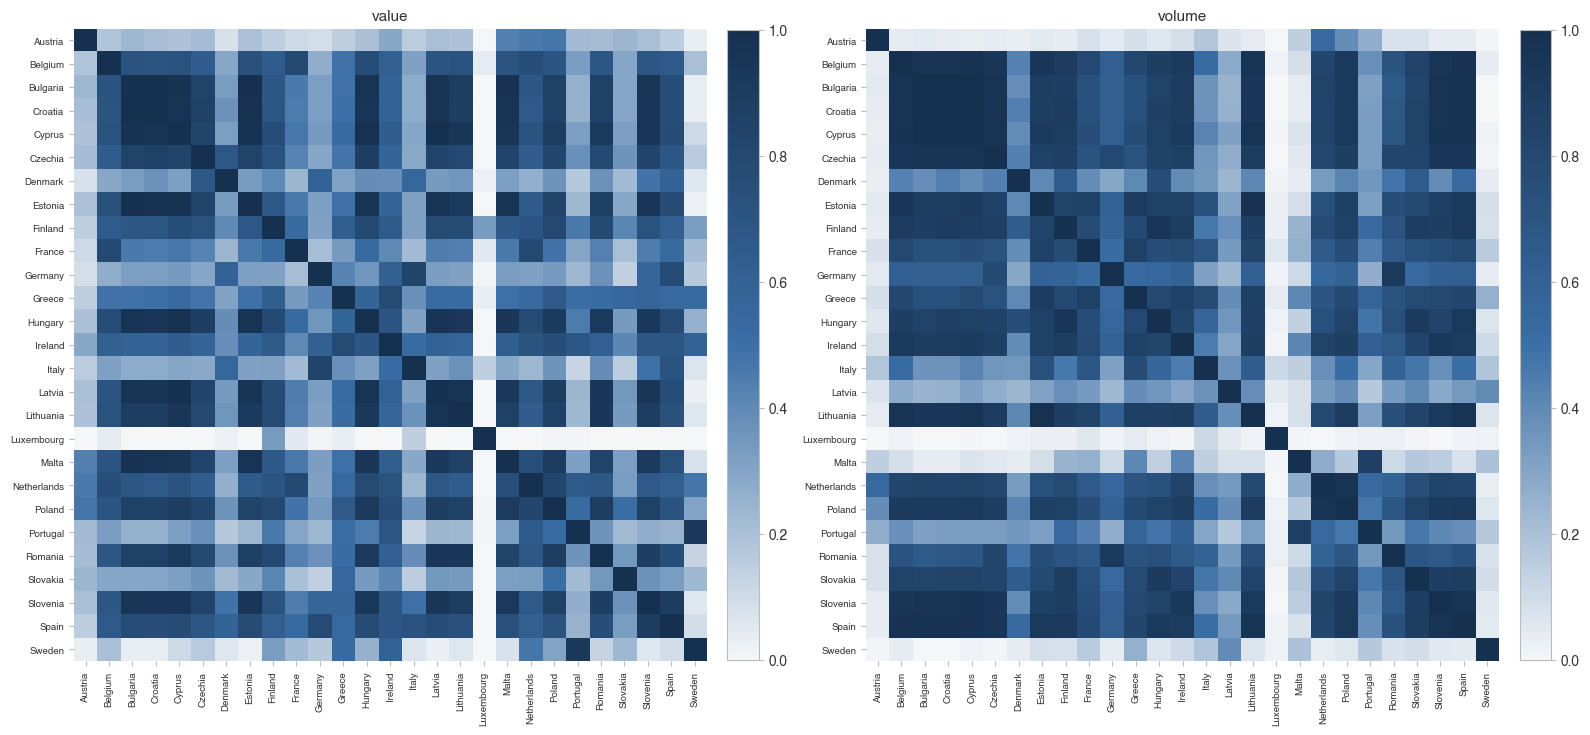

In [9]:
# --- figure: EU-27 pairwise sourcing cosine similarity, value and volume ---
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(16, 7.4))
    for ax, (w, Ce) in zip(axes, [('value', C_eu), ('volume', C_eu_quant)]):
        im = ax.imshow(Ce.values, cmap=BLUES, vmin=0, vmax=1)
        ax.set_xticks(range(len(Ce))); ax.set_xticklabels(Ce.index, rotation=90, fontsize=7)
        ax.set_yticks(range(len(Ce))); ax.set_yticklabels(Ce.index, fontsize=7)
        ax.spines[:].set_visible(False)
        ax.set_title(W_LAB[w], **SUB)
        fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
    plt.tight_layout()
    save(fig, 'cosine.png'); plt.show()

## 1b. Significance test - marginal-preserving null (herding)

A cosine of 0.50 means nothing on its own. We test it against a **null** that keeps two things fixed
and destroys only the *coordination* between countries:

- each importer keeps its **concentration profile** (its sorted import weights),
- each supplier keeps its **global export weight** (so China / India stay just as likely to be picked).

We redraw *which* suppliers each EU country buys from under that null, recompute the EU-27 mean pairwise
cosine, repeat many times, and compare the observed value to the null distribution.
If observed > null -> EU countries herd onto the same suppliers **beyond** what market structure implies.
If observed ~ null -> the overlap is fully explained by China/India's dominance (no *extra* systemic herding).

In [10]:
# --- helpers ---
def mean_pairwise_cosine(A):
    # A: rows = sourcing vectors. Returns the mean cosine over the distinct pairs.
    nrm = np.linalg.norm(A, axis=1, keepdims=True)
    An = A / np.where(nrm == 0, 1, nrm)
    Cm = An @ An.T
    h = np.triu_indices(len(A), 1)
    return Cm[h].mean()

def permutation_null(S_mat, export_share, eu_list, N=1000, seed=0):
    rng = np.random.default_rng(seed)
    exporters = list(S_mat.columns)
    p = export_share.reindex(exporters).fillna(0).values     # global export share per supplier
    col_of = {c: k for k, c in enumerate(exporters)}
    S_eu = S_mat.loc[eu_list].values
    observed = mean_pairwise_cosine(S_eu)

    def redraw(row, self_name):
        w = np.sort(row[row > 0])[::-1]          # keep the concentration profile (weights)
        pp = p.copy()
        if self_name in col_of:                  # a country never supplies itself
            pp[col_of[self_name]] = 0
        pp = pp / pp.sum()
        pick = rng.choice(len(exporters), size=len(w), replace=False, p=pp)
        v = np.zeros(len(exporters)); v[pick] = w
        return v

    null = np.empty(N)
    for k in range(N):
        A = np.array([redraw(S_eu[i], eu_list[i]) for i in range(len(eu_list))])
        null[k] = mean_pairwise_cosine(A)
    pval = (null >= observed).mean()
    return observed, null, pval

In [11]:
# --- VALUE ---
exp_share_v = M.sum(axis=0) / M.sum(axis=0).sum()           # global export share (value)
obs_v, null_v, p_v = permutation_null(S, exp_share_v, eu27, N=1000)
print(f'VALUE    -> observed={obs_v:.3f}  null mean={null_v.mean():.3f}  '
      f'sd={null_v.std():.3f}  95th={np.percentile(null_v,95):.3f}  p(null>=obs)={p_v:.4f}')

VALUE    -> observed=0.501  null mean=0.385  sd=0.053  95th=0.479  p(null>=obs)=0.0200


In [12]:
# --- QUANTITY ---
exp_share_q = M_quant.sum(axis=0) / M_quant.sum(axis=0).sum()   # global export share (quantity)
obs_q, null_q, p_q = permutation_null(S_quant, exp_share_q, eu27, N=1000)
print(f'QUANTITY -> observed={obs_q:.3f}  null mean={null_q.mean():.3f}  '
      f'sd={null_q.std():.3f}  95th={np.percentile(null_q,95):.3f}  p(null>=obs)={p_q:.4f}')

QUANTITY -> observed=0.524  null mean=0.525  sd=0.072  95th=0.649  p(null>=obs)=0.4970


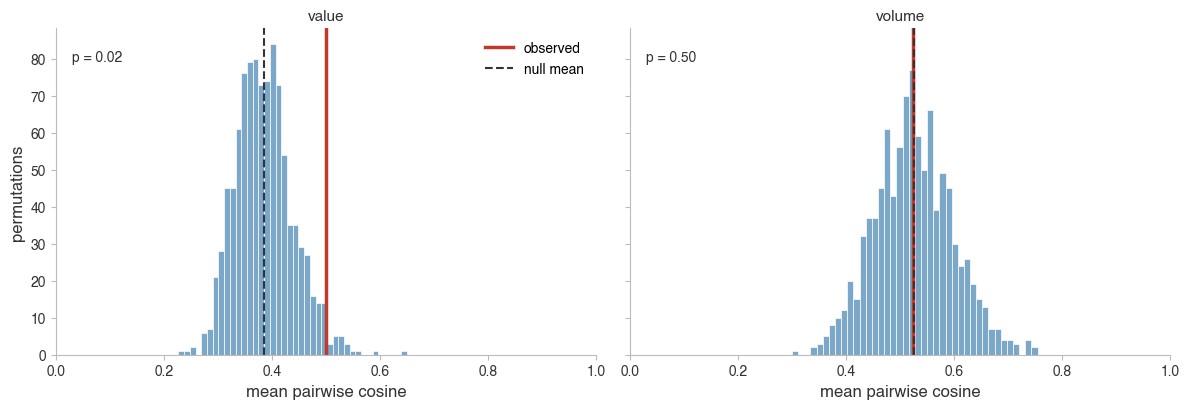

In [13]:
# --- figure: EU-27 mean pairwise cosine against the marginal-preserving null, value and volume ---
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, (w, obs, null, pv) in zip(axes, [('value', obs_v, null_v, p_v), ('volume', obs_q, null_q, p_q)]):
        ax.hist(null, bins=40, color='#7ba7c9', edgecolor='white', linewidth=.5)
        ax.axvline(obs, color=NONEU_C, lw=2.5, label='observed')
        ax.axvline(null.mean(), color='#333333', lw=1.5, ls='--', label='null mean')
        ax.text(.03, .9, f'p = {pv:.2f}', transform=ax.transAxes, fontsize=10, color='#333333')
        ax.set_xlim(0, 1); ax.set_xlabel('mean pairwise cosine')
        ax.set_title(W_LAB[w], **SUB)
    axes[0].set_ylabel('permutations'); axes[0].legend(loc='upper right')
    plt.tight_layout()
    save(fig, 'cosine_null.png'); plt.show()

# 2. Import exposure

`exposure_i = imports_i / (imports_i + exports_i)`, pooled over the 4 antibiotic codes, by value and by volume.
Low = the country makes / re-exports a lot; high (~1) = it is a pure importer.
This is a **scalar per country** (not a matrix) - it is the axis of the fragility map and the weight
used later in the shock cascade, it is *not* used in the cosine. No `str` version: `str` covers imports only.

In [14]:
# imports and exports per country (value, pooled over the 4 codes)
imports_by_country = df.groupby('importer_name')['value_1000_usd'].sum()
exports_by_country = df.groupby('exporter_name')['value_1000_usd'].sum()

exposure = pd.DataFrame({'imports': imports_by_country, 'exports': exports_by_country}).fillna(0)
exposure['exposure'] = exposure['imports'] / (exposure['imports'] + exposure['exports'])

exposure_eu = exposure.loc[eu27].sort_values('exposure', ascending=False)
print('EU-27 mean exposure:', round(exposure_eu['exposure'].mean(), 3))
exposure_eu.round(3)

EU-27 mean exposure: 0.611


,imports,exports,exposure
Luxembourg,3149.340,35.192,0.989
Finland,868.167,26.505,0.970
Greece,79205.665,2639.649,0.968
Estonia,4452.284,242.398,0.948
Cyprus,15487.130,850.528,0.948
Latvia,1179.972,97.303,0.924
Poland,24782.886,2602.244,0.905
Lithuania,1744.290,489.158,0.781
Portugal,128059.555,40448.208,0.760
France,382312.941,132905.814,0.742


In [15]:
# --- EU-27 import exposure by VOLUME (tonnes) ---
imp_q = df.groupby('importer_name')['quantity_tonnes'].sum()
exp_q = df.groupby('exporter_name')['quantity_tonnes'].sum()
exposure_q = pd.DataFrame({'imports': imp_q, 'exports': exp_q}).fillna(0)
exposure_q['exposure'] = exposure_q['imports'] / (exposure_q['imports'] + exposure_q['exports'])
print('EU-27 mean exposure (volume):', round(exposure_q.loc[eu27, 'exposure'].mean(), 3))

EU-27 mean exposure (volume): 0.659


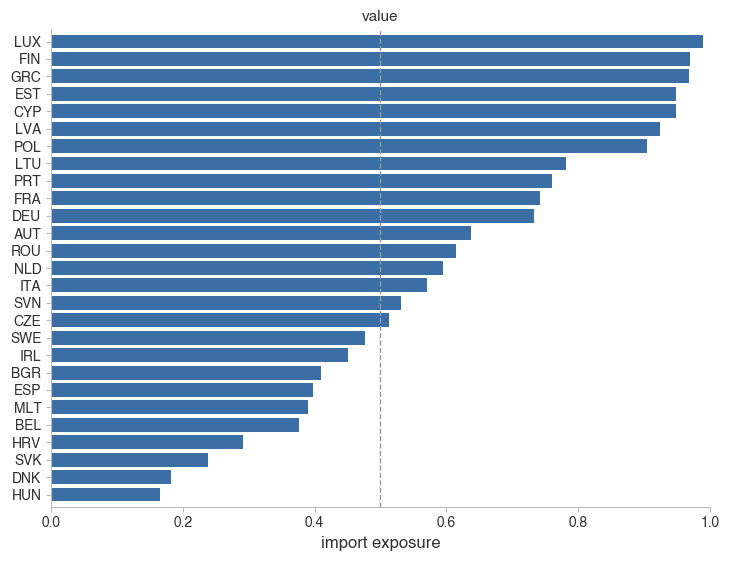

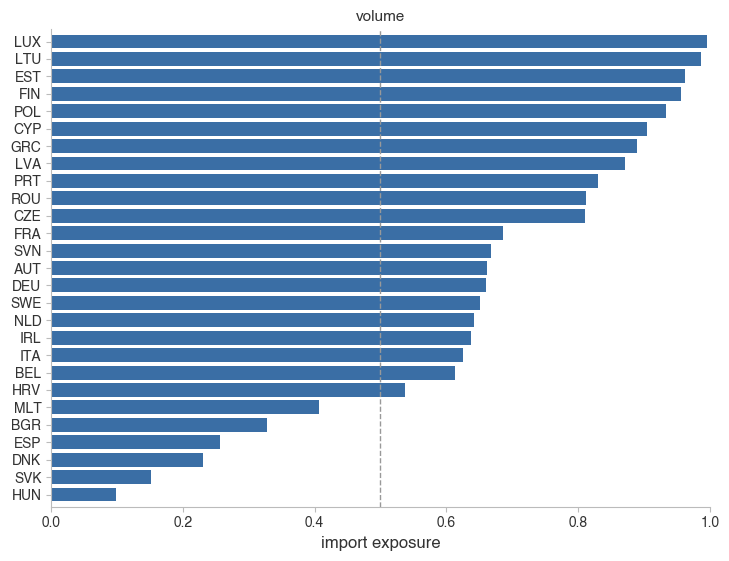

In [16]:
# --- figure: EU-27 import exposure, one file per weight ---
expo = {'value': exposure.loc[eu27, 'exposure'].rename(index=NAME_ISO),
        'volume': exposure_q.loc[eu27, 'exposure'].rename(index=NAME_ISO)}

def exposure_fig(w):
    d = expo[w].sort_values()
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(8.5, 6.2))
        ax.barh(d.index, d.values, height=.8, color=EU_C)
        ax.axvline(.5, ls='--', color='#999999', lw=1)
        ax.set_xlim(0, 1); ax.set_ylim(-.7, len(d) - .3)
        ax.set_xlabel('import exposure')
        ax.set_title(W_LAB[w], **SUB)
        save(fig, f'exposure_{w}.png'); plt.show()

for w in expo:
    exposure_fig(w)

# 3. Largest supplier and supplier concentration

How exposed is each EU country to the loss of **one** supplier? Two standard measures of source
concentration, computed on the sourcing shares for each weight (value, volume and risk-adjusted `str`):

- **HHI** = sum over suppliers of (import share)^2. 1 = single supplier, ~0 = perfectly diversified.
  It is the y-axis of the fragility map (section 4).
- **Top-1 share** = the share coming from the single largest supplier. A country is **single-sourced**
  if this exceeds 50%.

We also flag whether that largest supplier is **extra-EU** (red in the figure) or inside the EU (blue).

In [17]:
# --- largest supplier and HHI per EU-27 country, pooled over the 4 classes, for each weight ---
def single_sourcing(w):
    s = SH_EU[w]
    top = s.idxmax(axis=1)
    return pd.DataFrame({'HHI': (s ** 2).sum(axis=1),
                         'top1_supplier': top.map(lambda c: ISO_NAME.get(c, c)),
                         'top1_share': s.max(axis=1),
                         'top1_extra_EU': ~top.isin(EU27_ISO),
                         'n_suppliers': (s > 0).sum(axis=1)}).sort_values('top1_share', ascending=False)

single = {w: single_sourcing(w) for w in W_LAB}
for w, d in single.items():
    print(f'{W_LAB[w]:>20}: {int((d.top1_share > .5).sum())} / {len(d)} EU-27 countries get >50% from one supplier; '
          f'for {int(d.top1_extra_EU.sum())} the largest supplier is outside the EU')
single['volume'].round(3)

               value: 14 / 27 EU-27 countries get >50% from one supplier; for 21 the largest supplier is outside the EU
              volume: 13 / 27 EU-27 countries get >50% from one supplier; for 19 the largest supplier is outside the EU
 risk-adjusted (str): 9 / 27 EU-27 countries get >50% from one supplier; for 22 the largest supplier is outside the EU


,HHI,top1_supplier,top1_share,top1_extra_EU,n_suppliers
importer_iso3,,,,,
BGR,0.938,China,0.969,True,26
HRV,0.845,China,0.917,True,20
AUT,0.832,Spain,0.911,False,28
LUX,0.727,Ireland,0.849,False,11
CYP,0.699,China,0.831,True,16
CZE,0.534,China,0.703,True,26
SVN,0.496,China,0.682,True,20
MLT,0.480,Italy,0.679,False,20
EST,0.547,China,0.657,True,17


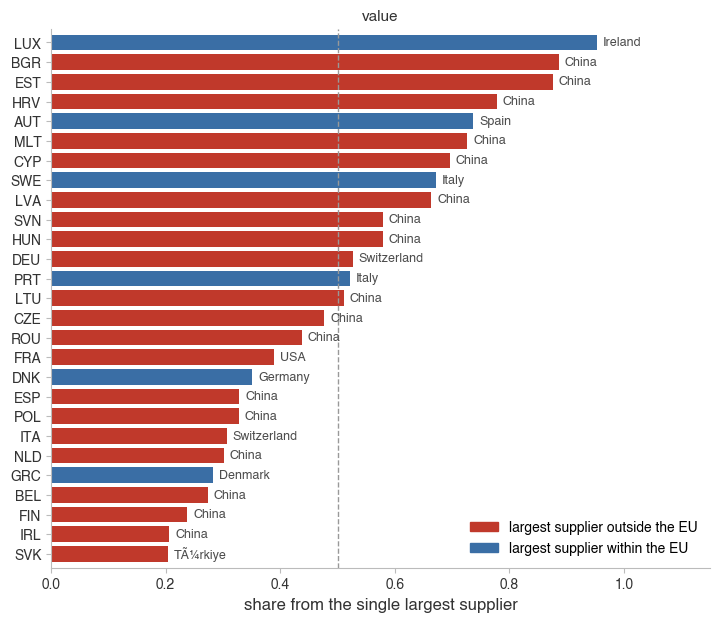

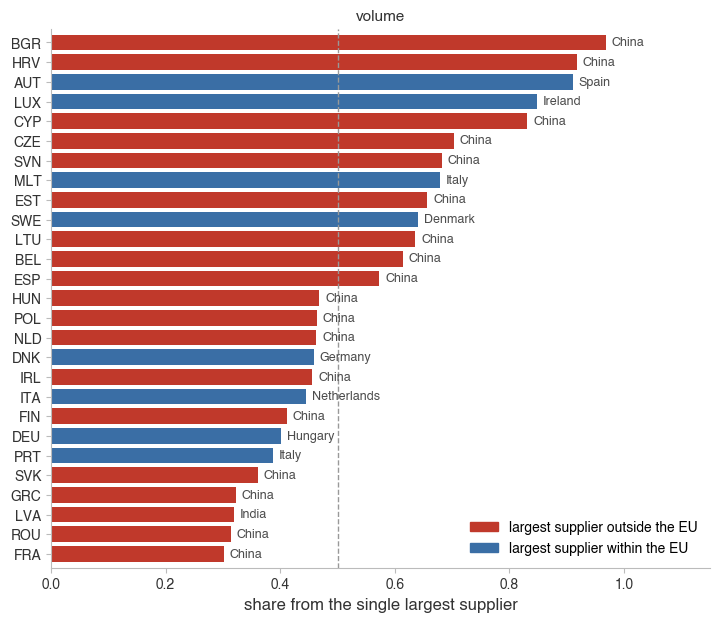

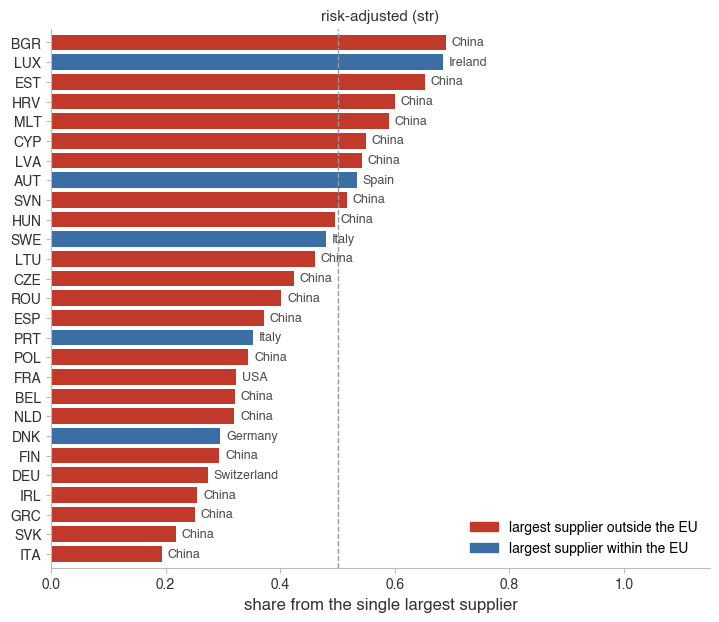

In [18]:
# --- figure: share from the single largest supplier per EU-27 country, one file per weight ---
def single_fig(w):
    d = single[w].sort_values('top1_share')
    y = np.arange(len(d))
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(8.5, 7))
        ax.barh(y, d.top1_share, height=.8, color=np.where(d.top1_extra_EU, NONEU_C, EU_C))
        for yi, (share, name) in enumerate(zip(d.top1_share, d.top1_supplier)):
            ax.text(share + .01, yi, name, va='center', fontsize=9, color='#4d4d4d')
        ax.axvline(.5, ls='--', color='#999999', lw=1)
        ax.set_yticks(y); ax.set_yticklabels(d.index)
        ax.set_xlim(0, 1.15); ax.set_ylim(-.7, len(d) - .3)
        ax.set_xlabel('share from the single largest supplier')
        ax.set_title(W_LAB[w], **SUB)
        ax.legend(handles=[Patch(color=NONEU_C, label='largest supplier outside the EU'),
                           Patch(color=EU_C, label='largest supplier within the EU')], loc='lower right')
        save(fig, f'single_sourcing_{w}.png'); plt.show()

for w in W_LAB:
    single_fig(w)

In [19]:
# --- per HS-6 class: top-1 supplier share, EU-27 x 4 classes ---
codes = sorted(raw.hs6_code.unique())
grid = pd.DataFrame(index=eu27, columns=codes, dtype=float)
for c in eu27:
    for hs in codes:
        b = raw[(raw.importer_name == c) & (raw.hs6_code == hs)].groupby('exporter_name').value_1000_usd.sum()
        grid.loc[c, hs] = (b.max() / b.sum()) if b.sum() > 0 else np.nan
print('EU-27 countries single-sourced (>50% from one supplier) per class:')
print((grid > 0.5).sum().rename('n_single_sourced').to_string())
grid.round(2)

EU-27 countries single-sourced (>50% from one supplier) per class:
294110    16
294130    17
294150    24
294190    10


,294110,294130,294150,294190
Austria,0.94,0.33,0.58,0.61
Belgium,0.53,0.51,0.44,0.22
Bulgaria,0.83,0.66,0.53,0.96
Croatia,0.35,0.64,0.99,0.47
Cyprus,0.80,0.88,0.54,0.61
Czechia,0.78,0.42,0.58,0.46
Denmark,0.50,0.96,1.00,0.36
Estonia,0.98,0.97,0.56,0.73
Finland,0.76,0.58,0.51,0.21
France,0.28,0.44,0.31,0.52


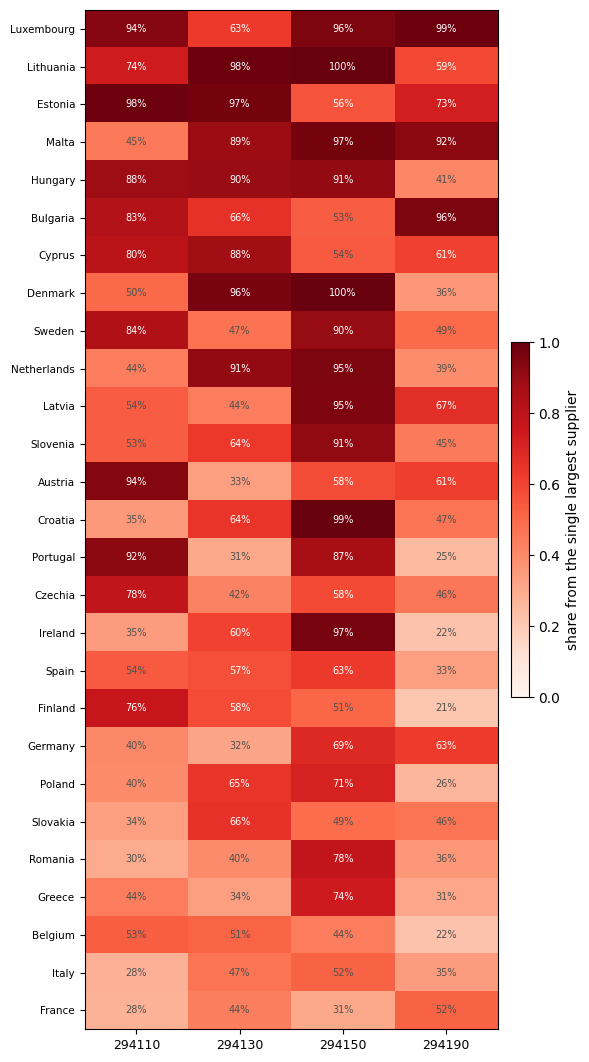

In [20]:
# --- heatmap: top-1 supplier share by country x class (value; exploratory, not saved) ---
import matplotlib.pyplot as plt
order = grid.mean(axis=1).sort_values(ascending=False).index
g = grid.loc[order]
fig, ax = plt.subplots(figsize=(6, .36 * len(g) + 1))
im = ax.imshow(g.values.astype(float), cmap='Reds', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(codes))); ax.set_xticklabels([str(h) for h in codes], rotation=0, fontsize=9)
ax.set_yticks(range(len(g))); ax.set_yticklabels(g.index, fontsize=7.5)
for i in range(len(g)):
    for k in range(len(codes)):
        v = g.values[i, k]
        if not np.isnan(v):
            ax.text(k, i, f'{v:.0%}', ha='center', va='center', fontsize=7,
                    color='white' if v > 0.55 else '#52514e')
fig.colorbar(im, ax=ax, fraction=.04, pad=.03, label='share from the single largest supplier')
plt.tight_layout(); plt.show()

# 4. Fragility map - import exposure vs supplier concentration

Each EU-27 country is placed by its import exposure (section 2) and the HHI of its import shares (section 3);
bubble area is proportional to its total antibiotic imports. Countries in the upper right are both
import-dependent and concentrated on few suppliers. Value and volume only, since exposure needs exports.

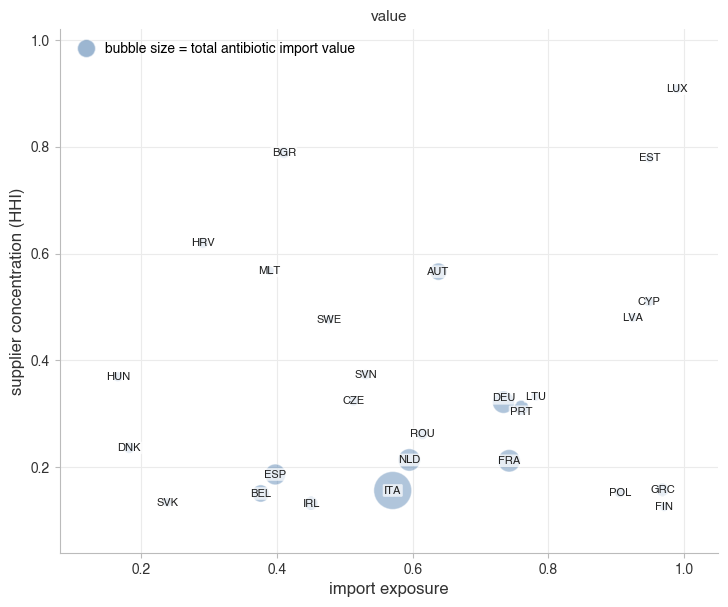

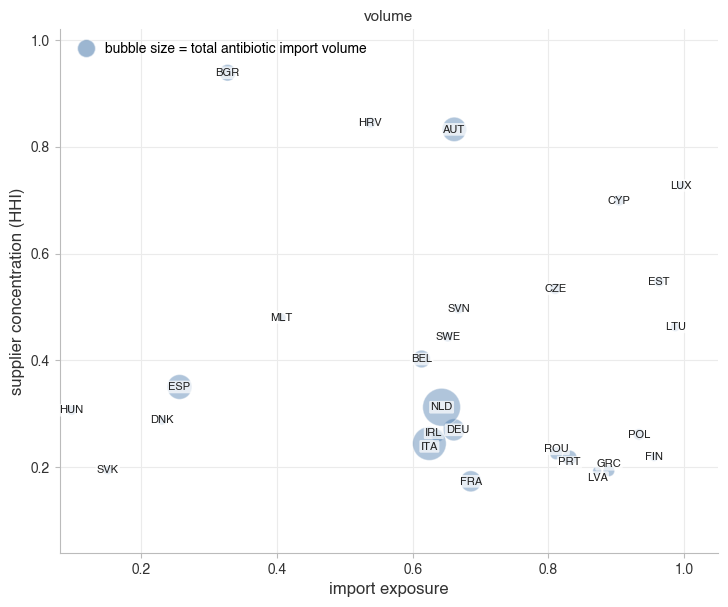

In [21]:
# --- figure: fragility map, import exposure vs supplier concentration, one file per weight ---
def repel_labels(ax, texts, x, y):
    # push overlapping labels apart, pull them back towards their bubble, and draw a thin leader
    # line to labels that ended up far from it
    ax.figure.canvas.draw(); rnd = ax.figure.canvas.get_renderer()
    b0 = [t.get_window_extent(rnd) for t in texts]
    cx = np.array([(b.x0 + b.x1) / 2 for b in b0]); cy = np.array([(b.y0 + b.y1) / 2 for b in b0])
    hw = np.array([(b.x1 - b.x0) / 2 for b in b0]) + 1.5
    hh = np.array([(b.y1 - b.y0) / 2 for b in b0]) + 1.5
    anchor = np.array([ax.transData.transform((xi, yi)) for xi, yi in zip(x, y)])
    for _ in range(600):
        moved = False
        for a in range(len(texts)):
            for b in range(a + 1, len(texts)):
                dx = cx[a] - cx[b]; dy = cy[a] - cy[b]
                ox = hw[a] + hw[b] - abs(dx); oy = hh[a] + hh[b] - abs(dy)
                if ox > 0 and oy > 0:
                    moved = True
                    if ox < oy:
                        s = ox / 2 + 0.4; sgn = 1 if dx >= 0 else -1; cx[a] += s * sgn; cx[b] -= s * sgn
                    else:
                        s = oy / 2 + 0.4; sgn = 1 if dy >= 0 else -1; cy[a] += s * sgn; cy[b] -= s * sgn
        cx += (anchor[:, 0] - cx) * 0.02; cy += (anchor[:, 1] - cy) * 0.02
        if not moved: break
    inv = ax.transData.inverted()
    for t, X, Y, ax_, ay_ in zip(texts, cx, cy, anchor[:, 0], anchor[:, 1]):
        t.set_position(inv.transform((X, Y)))
        if np.hypot(X - ax_, Y - ay_) > 8:
            dxy = inv.transform((X, Y)); axy = inv.transform((ax_, ay_))
            ax.plot([axy[0], dxy[0]], [axy[1], dxy[1]], color='#9a9a9a', lw=.5, zorder=1)

def fragility_fig(w):
    col = {'value': 'value_1000_usd', 'volume': 'quantity_tonnes'}[w]
    d = pd.DataFrame({'x': expo[w], 'y': single[w].HHI, 'imp': t_eu.groupby('importer_iso3')[col].sum()}).dropna()
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(8.5, 6.8))
        ax.grid(True)
        ax.scatter(d.x, d.y, s=d.imp / d.imp.max() * 700 + 40, color=EU_C, alpha=.4, edgecolor='white',
                   linewidth=.8, zorder=2)
        ax.set_xlim(.08, 1.05); ax.set_ylim(.04, 1.02)
        texts = [ax.text(xi, yi, c, fontsize=8, color='#222222', ha='center', va='center', zorder=4,
                         bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=.7))
                 for c, xi, yi in zip(d.index, d.x, d.y)]
        repel_labels(ax, texts, d.x.values, d.y.values)
        ax.set_xlabel('import exposure'); ax.set_ylabel('supplier concentration (HHI)')
        ax.set_title(W_LAB[w], **SUB)
        ax.legend(handles=[Line2D([0], [0], marker='o', ls='', markerfacecolor=EU_C, markeredgecolor='white',
                                  markersize=13, alpha=.5, label=f'bubble size = total antibiotic import {w}')],
                  loc='upper left', fontsize=10, handletextpad=.4)
        save(fig, f'fragility_{w}.png'); plt.show()

for w in expo:
    fragility_fig(w)

# 5. China + India shock - direct and cascading (network) loss

**Question.** If a big producer (China, India) stops exporting, what fraction of each country's antibiotic
supply is lost - counting not only what it buys *directly* from that producer, but the shock **cascading**
through intermediaries (my suppliers also depend on China, so they cannot fully cover me)?

**Step 1 - Sourcing shares `S`.** For each importer $i$, the share of its imports from each exporter $j$:
$$S_{ij} = \frac{\text{$i$ imports from $j$}}{\text{$i$'s total imports}}, \qquad \sum_j S_{ij}=1.$$

**Step 2 - Import dependence `exposure`.** Domestic production buffers the shock. Trade-only proxy:
$$\text{exposure}_i = \frac{\text{imports}_i}{\text{imports}_i + \text{exports}_i}.$$
Big net exporter -> low; pure importer -> $\approx 1$.

**Step 3 - Consumption-source matrix `P`.** Of $i$'s *total* consumption, the fraction effectively from $j$:
$$P_{ij} = \text{exposure}_i \cdot S_{ij}, \qquad P = \mathrm{diag}(\text{exposure})\,S.$$
Row $i$ sums to $\text{exposure}_i$; the remaining $1-\text{exposure}_i$ is domestic production, which the
import shock cannot touch (the buffer).

**Step 4 - The cascade.** Remove producer $s$. The lost fraction $x_i$ obeys
$$x_i = \underbrace{P_{is}}_{\text{direct}} + \underbrace{\sum_k P_{ik}\,x_k}_{\text{indirect}} \;\Rightarrow\; (I-P)\,x = P_{:,s} \;\Rightarrow\; \boxed{x = (I-P)^{-1} P_{:,s}}.$$
$(I-P)^{-1} = I + P + P^2 + P^3 + \dots$ is the **Leontief inverse**: direct + 1-hop + 2-hop + ... through
the supplier network. It converges because domestic buffers keep the spectral radius of $P$ below 1.

**Step 5 - Combined shock (China + India).** Remove both rows/columns; direct loss = what each country
bought from *either*; solve the same system.

**Output.** $x_i \in [0, \text{exposure}_i]$ = fraction of $i$'s antibiotic supply lost; the **indirect**
part ($x_i - \text{direct}$) is the *hidden* network exposure you cannot see from direct imports.

In [22]:
# --- build the square country x country matrices S, exposure, P (pooled 4 classes) ---
def build_P(metric):
    f = df.groupby(['importer_name', 'exporter_name'])[metric].sum().reset_index()
    countries = sorted(set(f.importer_name) | set(f.exporter_name))
    idx = {c: k for k, c in enumerate(countries)}
    n = len(countries)
    F = np.zeros((n, n))
    F[f.importer_name.map(idx), f.exporter_name.map(idx)] = f[metric].fillna(0).values   # F[i,j] = i imports from j
    imports = F.sum(1)                                   # row sum
    exports = F.sum(0)                                   # column sum
    S = np.divide(F, imports[:, None], out=np.zeros_like(F), where=imports[:, None] > 0)  # row-normalized shares
    exposure = np.divide(imports, imports + exports, out=np.zeros_like(imports), where=(imports + exports) > 0)
    P = exposure[:, None] * S                            # consumption-source matrix
    return countries, idx, S, exposure, P

def shock(P, countries, idx, targets):
    '''Fraction of each country's consumption lost if `targets` stop exporting (direct + cascaded).'''
    tset = [idx[t] for t in targets if t in idx]
    keep = [k for k in range(len(countries)) if k not in tset]
    direct = P[np.ix_(keep, tset)].sum(1)                                   # direct loss from the shocked producers
    total  = np.linalg.solve(np.eye(len(keep)) - P[np.ix_(keep, keep)], direct)   # Leontief inverse solve
    res = pd.DataFrame({'direct': direct, 'total': total},
                       index=[countries[k] for k in keep])
    res['indirect'] = (res.total - res.direct).clip(lower=0)
    return res

SCEN = {'China': ['China'], 'India': ['India'], 'China+India': ['China', 'India']}

## Shock results - by import VALUE

In [23]:
countries, idx, S2, exposure, P = build_P('value_1000_usd')
sh = {name: shock(P, countries, idx, t) for name, t in SCEN.items()}

# EU-27 decomposition: combined shock split into direct + indirect, plus China-only / India-only totals
dec = pd.DataFrame({
    'direct':     sh['China+India'].direct,
    'indirect':   sh['China+India'].indirect,
    'combined':   sh['China+India'].total,
    'China_only': sh['China'].total,
    'India_only': sh['India'].total,
}).loc[eu27].sort_values('combined', ascending=False)

print('EU-27 mean fraction of antibiotic supply lost (VALUE):')
print(pd.Series({k: sh[k]['total'].loc[eu27].mean() for k in SCEN}).round(3).to_string())
print(f"\nChina+India, EU-27: direct={dec.direct.mean():.3f}  indirect/hidden={dec.indirect.mean():.3f}  "
      f"-> indirect is {dec.indirect.sum()/dec.combined.sum()*100:.0f}% of total")
dec.round(3)

EU-27 mean fraction of antibiotic supply lost (VALUE):
China          0.310
India          0.055
China+India    0.334

China+India, EU-27: direct=0.265  indirect/hidden=0.069  -> indirect is 21% of total


,direct,indirect,combined,China_only,India_only
Estonia,0.831,0.036,0.867,0.863,0.022
Cyprus,0.787,0.050,0.837,0.770,0.151
Latvia,0.787,0.034,0.821,0.735,0.191
Lithuania,0.547,0.083,0.630,0.553,0.170
Finland,0.376,0.118,0.493,0.414,0.171
Poland,0.379,0.103,0.482,0.436,0.103
Romania,0.389,0.055,0.445,0.383,0.133
Bulgaria,0.365,0.010,0.375,0.373,0.009
Slovenia,0.346,0.024,0.370,0.350,0.049
Greece,0.216,0.124,0.340,0.315,0.057


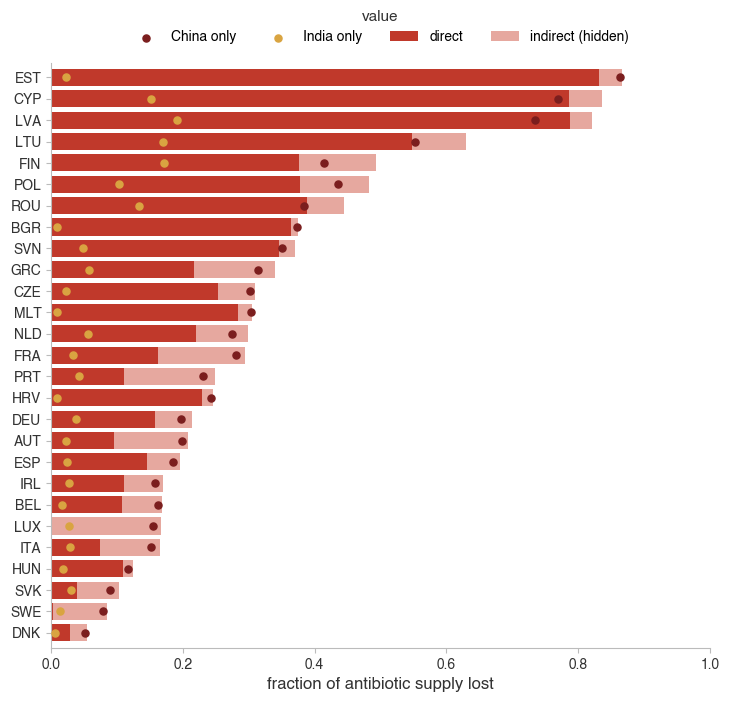

In [24]:
# --- figure: China + India shock per EU-27 country, direct vs indirect loss (VALUE) ---
def shock_fig(dec, w):
    d = dec.rename(index=NAME_ISO).sort_values('combined')
    y = np.arange(len(d))
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(8.5, 7.6))
        direct = ax.barh(y, d.direct, height=.8, color=NONEU_C)
        indirect = ax.barh(y, d.indirect, left=d.direct, height=.8, color='#e6a89f')
        cn = ax.scatter(d.China_only, y, s=26, color='#7b1e1e', zorder=3)
        ind = ax.scatter(d.India_only, y, s=26, color='#d9a441', zorder=3)
        ax.set_yticks(y); ax.set_yticklabels(d.index); ax.set_ylim(-.7, len(d) - .3)
        ax.set_xlim(0, 1); ax.set_xlabel('fraction of antibiotic supply lost')
        ax.legend([cn, ind, direct, indirect], ['China only', 'India only', 'direct', 'indirect (hidden)'],
                  loc='lower center', bbox_to_anchor=(.5, 1.01), ncol=4, fontsize=10)
        ax.set_title(W_LAB[w], pad=30, **SUB)
        save(fig, f'shock_{w}.png'); plt.show()

shock_fig(dec, 'value')

## Shock results - by import VOLUME (tonnes)

,direct,total,indirect
Afghanistan,0.046195,0.764722,0.718527
Albania,0.482780,0.692919,0.210138
Algeria,0.707699,0.860942,0.153242
Andorra,0.000000,0.000000,0.000000
Angola,0.123647,0.496406,0.372759
...,...,...,...
Venezuela,0.970325,0.994237,0.023911
Viet Nam,0.818339,0.910838,0.092499
Yemen,0.811628,0.921916,0.110289
Zambia,0.132777,0.687541,0.554764


In [49]:
countriesV, idxV, SV, exposureV, PV = build_P('quantity_tonnes')
shV = {name: shock(PV, countriesV, idxV, t) for name, t in SCEN.items()}
euV = [c for c in eu27 if c in shV['China+India'].index]

decV = pd.DataFrame({
    'direct':     shV['China+India'].direct,
    'indirect':   shV['China+India'].indirect,
    'combined':   shV['China+India'].total,
    'China_only': shV['China'].total,
    'India_only': shV['India'].total,
}).loc[euV].sort_values('combined', ascending=False)

print('EU-27 mean fraction of antibiotic supply lost (VOLUME):')
print(pd.Series({k: shV[k]['total'].loc[euV].mean() for k in SCEN}).round(3).to_string())
print(f"\nChina+India, EU-27: direct={decV.direct.mean():.3f}  indirect/hidden={decV.indirect.mean():.3f}  "
      f"-> indirect is {decV.indirect.sum()/decV.combined.sum()*100:.0f}% of total \n" 
      f"-> direct is {decV.direct.sum()/decV.combined.sum()*100:.0f}% of total")
decV.round(3)

EU-27 mean fraction of antibiotic supply lost (VOLUME):
China          0.397
India          0.041
China+India    0.412

China+India, EU-27: direct=0.296  indirect/hidden=0.116  -> indirect is 28% of total 
-> direct is 72% of total


,direct,indirect,combined,China_only,India_only
Cyprus,0.810,0.037,0.847,0.822,0.069
Lithuania,0.705,0.132,0.838,0.801,0.098
Estonia,0.632,0.139,0.771,0.764,0.022
Finland,0.437,0.198,0.635,0.608,0.072
Czechia,0.588,0.032,0.620,0.612,0.025
Poland,0.474,0.140,0.614,0.594,0.055
Latvia,0.370,0.185,0.555,0.440,0.290
Slovenia,0.479,0.043,0.522,0.511,0.031
Greece,0.304,0.216,0.520,0.505,0.042
Croatia,0.495,0.013,0.508,0.507,0.006


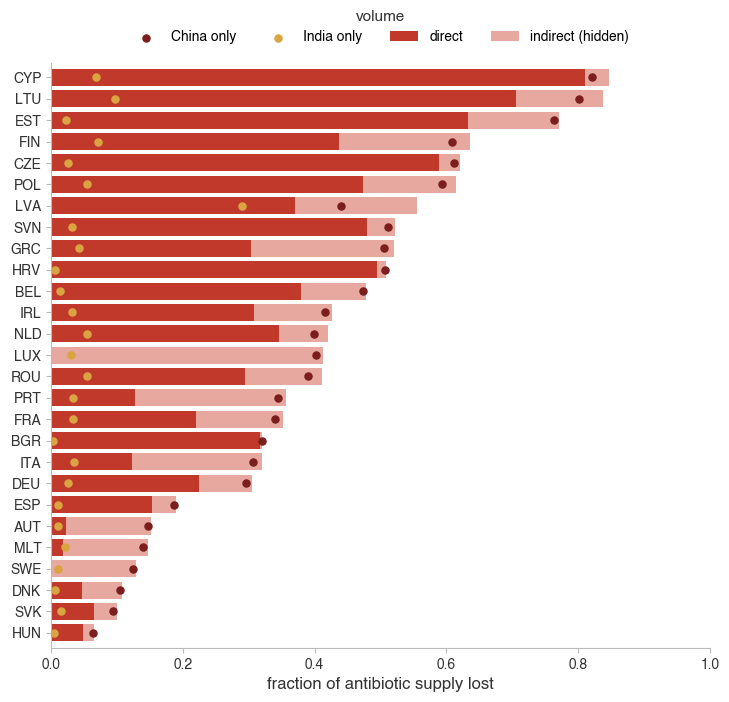

In [26]:
# --- figure: China + India shock per EU-27 country, direct vs indirect loss (VOLUME) ---
shock_fig(decV, 'volume')

## 5b. Shock significance - is the hidden (indirect) cascade real?

The cascade numbers are deterministic point estimates, so on their own they are descriptive. The one
part that carries a *testable* claim is the **indirect / hidden** exposure: it asserts that dependence
*propagates through intermediaries*, not just that a lot of supply is lost. We test it against a
**marginal-preserving null** - the same "herding" logic used for the cosine, applied to the whole
sourcing matrix:

- each importer keeps its **concentration profile** (its sorted import weights) and its **exposure**,
- each supplier keeps its **global export weight** (so China / India stay just as likely to be picked),
- we only randomise **which** suppliers each country actually buys from, then rebuild
  $P=\mathrm{diag}(\text{exposure})\,S$ and recompute the China+India cascade.

**Statistic:** the EU-27 mean *indirect* share. If the observed indirect exposure sits **above** the
null distribution, the hidden cascade is a property of the real supplier *wiring* (e.g. EU hubs that
themselves depend on China and re-supply others), not an artefact of the marginals.

We report the one-sided $p=\Pr(\text{null}\ge\text{obs})$ and the standardised distance
$z=(\text{obs}-\overline{\text{null}})/\mathrm{sd}(\text{null})$.

In [27]:
# --- null machinery (reuses build_P / eu27 from the shock section) ---
def eu_mean_indirect(P, countries, idx, targets, eu27):
    tset = [idx[t] for t in targets if t in idx]
    keep = [k for k in range(len(countries)) if k not in tset]
    direct = P[np.ix_(keep, tset)].sum(1)
    total  = np.linalg.solve(np.eye(len(keep)) - P[np.ix_(keep, keep)], direct)
    indirect = np.clip(total - direct, 0, None)
    pos = {countries[k]: i for i, k in enumerate(keep)}
    return np.mean([indirect[pos[c]] for c in eu27 if c in pos])

def cascade_indirect_null(S, exposure, countries, idx, exp_share, targets, eu27, N=500, seed=0):
    rng = np.random.default_rng(seed)
    n = len(countries)
    p = exp_share.astype(float).copy()
    observed = eu_mean_indirect(exposure[:, None] * S, countries, idx, targets, eu27)
    null = np.empty(N)
    for it in range(N):
        Sn = np.zeros((n, n))
        for i in range(n):
            w = np.sort(S[i][S[i] > 0])[::-1]
            if w.size == 0:
                continue
            pp = p.copy(); pp[i] = 0.0
            npos = int((pp > 0).sum())
            if npos == 0:
                continue
            m = min(w.size, npos)
            pp = pp / pp.sum()
            pick = rng.choice(n, size=m, replace=False, p=pp)
            Sn[i, pick] = w[:m]
        null[it] = eu_mean_indirect(exposure[:, None] * Sn, countries, idx, targets, eu27)
    pval = (null >= observed).mean()
    z = (observed - null.mean()) / null.std()
    return observed, null, pval, z

TGT = ['China', 'India']

In [28]:
# --- VALUE ---   (uses countries, idx, S2, exposure from the value shock cell)
exp_share_v = np.array([df.groupby('exporter_name')['value_1000_usd'].sum().get(c, 0.0) for c in countries])
obs_iv, null_iv, p_iv, z_iv = cascade_indirect_null(S2, exposure, countries, idx, exp_share_v, TGT, eu27, N=500, seed=0)
print(f'VALUE   indirect: observed={obs_iv:.3f}  null mean={null_iv.mean():.3f}  sd={null_iv.std():.3f}  '
      f'95th={np.percentile(null_iv,95):.3f}  p(null>=obs)={p_iv:.4f}  z={z_iv:.2f}')

VALUE   indirect: observed=0.069  null mean=0.088  sd=0.013  95th=0.110  p(null>=obs)=0.9480  z=-1.50


In [29]:
# --- VOLUME ---  (uses countriesV, idxV, SV, exposureV from the volume shock cell)
exp_share_q = np.array([df.groupby('exporter_name')['quantity_tonnes'].sum().get(c, 0.0) for c in countriesV])
obs_iq, null_iq, p_iq, z_iq = cascade_indirect_null(SV, exposureV, countriesV, idxV, exp_share_q, TGT, euV, N=500, seed=0)
print(f'VOLUME  indirect: observed={obs_iq:.3f}  null mean={null_iq.mean():.3f}  sd={null_iq.std():.3f}  '
      f'95th={np.percentile(null_iq,95):.3f}  p(null>=obs)={p_iq:.4f}  z={z_iq:.2f}')

VOLUME  indirect: observed=0.116  null mean=0.113  sd=0.016  95th=0.140  p(null>=obs)=0.4040  z=0.20


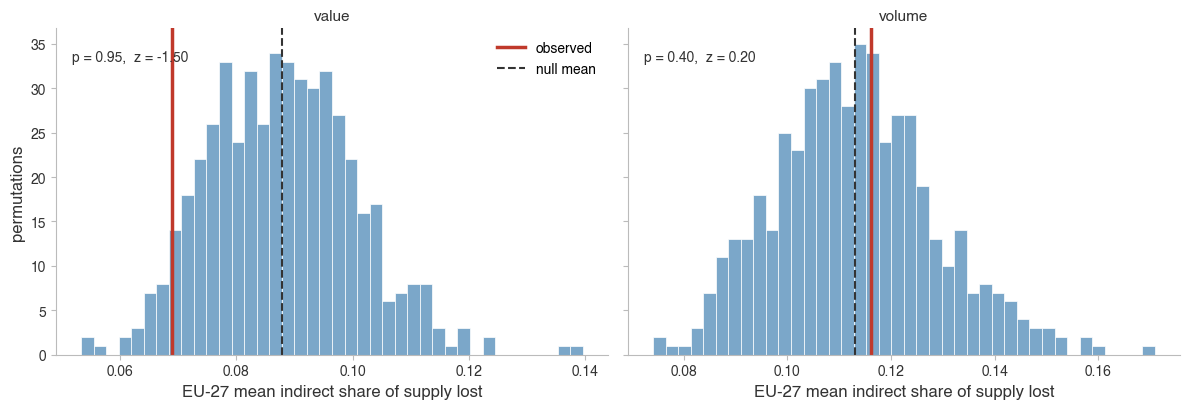

In [30]:
# --- plot both null distributions with the observed indirect exposure (not saved) ---
with plt.rc_context(STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
    for ax, (w, obs, null, pv, z) in zip(axes, [('value', obs_iv, null_iv, p_iv, z_iv),
                                                ('volume', obs_iq, null_iq, p_iq, z_iq)]):
        ax.hist(null, bins=40, color='#7ba7c9', edgecolor='white', linewidth=.5)
        ax.axvline(obs, color=NONEU_C, lw=2.5, label='observed')
        ax.axvline(null.mean(), color='#333333', lw=1.5, ls='--', label='null mean')
        ax.text(.03, .9, f'p = {pv:.2f},  z = {z:.2f}', transform=ax.transAxes, fontsize=10, color='#333333')
        ax.set_xlabel('EU-27 mean indirect share of supply lost')
        ax.set_title(W_LAB[w], **SUB)
    axes[0].set_ylabel('permutations'); axes[0].legend(loc='upper right')
    plt.tight_layout(); plt.show()

# 6. Register vs trade - Germany (cosine similarity and correlation)

For every partner country *c* we have two numbers:

- **register share** - share of Germany's foreign API-manufacturing sites that are located in *c*
  (BfArM, step `Wirkstoffherstellung`, unique `pu_nummer` x country; the critical J01 substances that
  fall in the 4 antibiotic HS-6 lines),
- **trade share** - share of Germany's antibiotic imports (the 4 HS-6 lines, 2024) that come from *c*,
  measured either as **`str`** (Max/Elma's risk-weighted numbers) or as **volume** (raw BACI tonnes).

Two measures compare them:

- **cosine similarity** - how similar the two country mixes are (1 = identical, 0 = no country in common),
- **Pearson r** - correlation, across countries, between register share and trade share.

Both are computed for three partner groups (Germany always excluded): **all foreign** partners,
**EU-27** partners and **non-EU** partners, with shares recomputed within each group. EU-27 is the split
because intra-EU trade is single-market / customs-union trade, so Switzerland and the UK count as non-EU.
A country present on one side only counts as 0 on the other; groups with fewer than 5 countries are not
reported.

`str` is a share within one class (it does not sum to 1), so before pooling the 4 classes each class's
`str` is multiplied by Germany's import value in that class.

In [31]:
# --- register vector: BfArM API-manufacturing sites per country ---
from pathlib import Path
import numpy as np
import pandas as pd

def atc_to_hs(atc):
    # J01 ATC code -> antibiotic HS-6 line (None = not in heading 2941)
    if atc.startswith('J01C'):  return '294110'    # penicillins
    if atc.startswith('J01AA'): return '294130'    # tetracyclines
    if atc.startswith('J01FA'): return '294150'    # macrolides
    if atc[:4] in ('J01D', 'J01G') or atc[:5] in ('J01FF', 'J01XA', 'J01XB'):
        return '294190'                             # cephalosporins, aminoglycosides, lincosamides, glycopeptides, polymyxins
    return None

DE_TO_ISO = {
    'China':'CHN', 'Indien':'IND', 'Spanien':'ESP', 'Italien':'ITA', 'Deutschland':'DEU',
    'Österreich':'AUT', 'Slowenien':'SVN', 'Korea, Republik':'KOR', 'Südkorea':'KOR',
    'Vereinigtes Königreich':'GBR', 'Dänemark':'DNK', 'Ungarn':'HUN', 'Mexiko':'MEX',
    'Singapur':'SGP', 'Kroatien':'HRV', 'Portugal':'PRT', 'Irland':'IRL', 'Vereinigte Staaten':'USA',
    'Macao':'MAC', 'Malaysia':'MYS', 'Israel':'ISR', 'Puerto Rico':'USA',   # BACI reports Puerto Rico within USA
    'Japan':'JPN', 'Belgien':'BEL', 'Türkei':'TUR', 'Niederlande':'NLD', 'Slowakei':'SVK',
    'Ägypten':'EGY', 'Frankreich':'FRA', 'Schweden':'SWE',
}

bf = pd.read_csv(ROOT / 'data' / 'registers' / 'raw' / 'bfarm_api_origin_critical_J01_LONG.csv')
bf = bf[bf.role == 'Wirkstoffherstellung'].copy()
bf['iso'] = bf.land.map(DE_TO_ISO)
bf['hs']  = bf.atc_code.map(atc_to_hs)
print('register countries not mapped to ISO-3:', int(bf.iso.isna().sum()))
bf = bf[bf.hs.notna()]

# sites[hs][country] = number of unique API sites; 'pooled' = unique sites over the 4 classes
sites = {hs: g.drop_duplicates(['pu_nummer', 'iso']).iso.value_counts() for hs, g in bf.groupby('hs')}
sites['pooled'] = bf.drop_duplicates(['pu_nummer', 'iso']).iso.value_counts()
print(f"{bf.atc_code.nunique()} substances, {int(sites['pooled'].sum())} unique API sites in {len(sites['pooled'])} countries")
pd.DataFrame(sites).fillna(0).astype(int).sort_values('pooled', ascending=False).head(10)

register countries not mapped to ISO-3: 0
24 substances, 182 unique API sites in 28 countries


,294110,294130,294150,294190,pooled
iso,,,,,
CHN,15,4,7,36,61
IND,4,0,8,12,24
ITA,8,0,4,11,20
ESP,10,0,3,2,14
USA,0,0,4,5,9
KOR,1,0,0,8,8
GBR,6,0,0,1,7
HUN,0,0,0,4,4
SVN,3,0,0,2,3


In [32]:
# --- trade vectors: Germany's imports by partner, str (Max/Elma) and volume (raw BACI tonnes) ---
t = raw[raw.importer_iso3 == 'DEU'].assign(hs=lambda d: d.hs6_code.astype(str))

flt = (pc.field('year') == 2024) & (pc.field('importer') == 'DEU') & pc.field('hs_code').isin(HS4)
st = pd.concat([pq.read_table(str(f), columns=['hs_code', 'exporter', 'str'], filters=flt).to_pandas()
                for f in sorted((DATA / 'sys_risk').glob('*.parquet'))], ignore_index=True)
# str is a share within one class: scale by Germany's import value in that class before pooling
st['str_flow'] = st['str'] * st.hs_code.map(t.groupby('hs').value_1000_usd.sum())

def trade_vec(hs, weight):
    classes = HS4 if hs == 'pooled' else [hs]
    if weight == 'str':
        v = st[st.hs_code.isin(classes)].groupby('exporter').str_flow.sum()
    else:
        v = t[t.hs.isin(classes)].groupby('exporter_iso3').quantity_tonnes.sum()
    return v.drop('DEU', errors='ignore')

In [33]:
# --- cosine similarity, Pearson r and Spearman rho, per class and pooled, for the three partner groups ---
from scipy.stats import pearsonr, spearmanr

CLASSES = {'294110': 'penicillins', '294130': 'tetracyclines', '294150': 'macrolides',
           '294190': 'other antibiotics', 'pooled': 'all 4 pooled'}
WEIGHTS = ['str', 'volume']
GROUPS  = ['all foreign', 'EU-27', 'non-EU']
MIN_N   = 5
MEASURES = ['cosine', 'pearson', 'spearman']

def compare(hs, weight, group):
    both = pd.concat({'register': sites[hs], 'trade': trade_vec(hs, weight)}, axis=1).fillna(0)
    both = both.drop('DEU', errors='ignore')
    if group == 'EU-27':  both = both[both.index.isin(EU27_ISO)]
    if group == 'non-EU': both = both[~both.index.isin(EU27_ISO)]
    both = both[(both > 0).any(axis=1)]
    if len(both) < MIN_N or (both.sum() == 0).any():
        return dict(cosine=np.nan, pearson=np.nan, p=np.nan, spearman=np.nan, p_s=np.nan, n=len(both)), both
    both = both / both.sum()                                   # shares within the group
    a, b = both.register.values, both.trade.values
    r, p = pearsonr(a, b)
    rho, p_s = spearmanr(a, b)                                  # rank-based: every country counts equally
    return dict(cosine=a @ b / (np.linalg.norm(a) * np.linalg.norm(b)), pearson=r, p=p,
                spearman=rho, p_s=p_s, n=len(both)), both

rows, shares = [], {}
for w in WEIGHTS:
    for g in GROUPS:
        for hs, name in CLASSES.items():
            res, both = compare(hs, w, g)
            rows.append(dict(weight=w, group=g, cls=name, **res))
            shares[w, g, hs] = both
rt = pd.DataFrame(rows)
rt.pivot_table(index=['weight', 'group'], columns='cls', values=['cosine', 'pearson', 'spearman', 'n'],
               sort=False, dropna=False).round(2)

cosine                                             \
cls                penicillins tetracyclines macrolides other antibiotics   
weight group                                                                
str    all foreign        0.81          0.79       0.79              0.57   
       EU-27              0.74          0.13       0.52              0.91   
       non-EU             0.90          0.99       0.86              0.53   
volume all foreign        0.20          0.84       0.57              0.91   
       EU-27              0.03          0.01       0.23              0.79   
       non-EU             0.89          0.99       0.62              0.92   

                                    pearson                           \
cls                all 4 pooled penicillins tetracyclines macrolides   
weight group                                                           
str    all foreign         0.72        0.76          0.74       0.77   
       EU-27               0.86        0.50         -0.34       0.08   
       non-EU              0.70        0.89          0.99       0.81   
volume all foreign         0.61        0.07          0.82       0.46   
       EU-27               0.25       -0.21         -0.16      -0.08   
       non-EU              0.94        0.90          0.98       0.46   

                                                     spearman                \
cls                other antibiotics all 4 pooled penicillins tetracyclines   
weight group                                                                  
str    all foreign              0.47         0.67        0.41          0.53   
       EU-27                    0.88         0.83        0.31         -0.13   
       non-EU                   0.37         0.64        0.37          0.70   
volume all foreign              0.90         0.57        0.32          0.20   
       EU-27                    0.73         0.11        0.29         -0.07   
       non-EU                   0.91         0.93        0.12          0.70   

                                                                       n  \
cls                macrolides other antibiotics all 4 pooled penicillins   
weight group                                                               
str    all foreign       0.24              0.38         0.46        22.0   
       EU-27            -0.25              0.15         0.51        10.0   
       non-EU            0.66              0.47         0.42        12.0   
volume all foreign       0.19              0.39         0.49        27.0   
       EU-27            -0.37              0.10         0.46        12.0   
       non-EU            0.59              0.50         0.42        15.0   

                                                                            
cls                tetracyclines macrolides other antibiotics all 4 pooled  
weight group                                                                
str    all foreign          17.0       15.0              25.0         36.0  
       EU-27                 7.0        7.0              14.0         18.0  
       non-EU               10.0        8.0              11.0         18.0  
volume all foreign          21.0       19.0              41.0         45.0  
       EU-27                11.0       10.0              18.0         19.0  
       non-EU               10.0        9.0              23.0         26.0

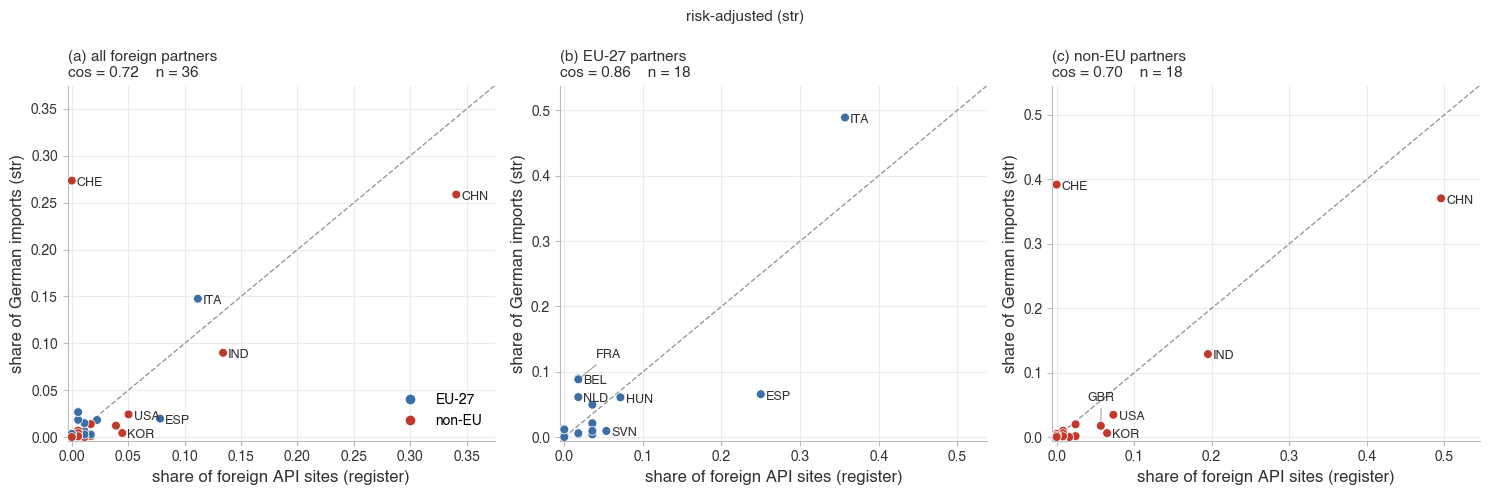

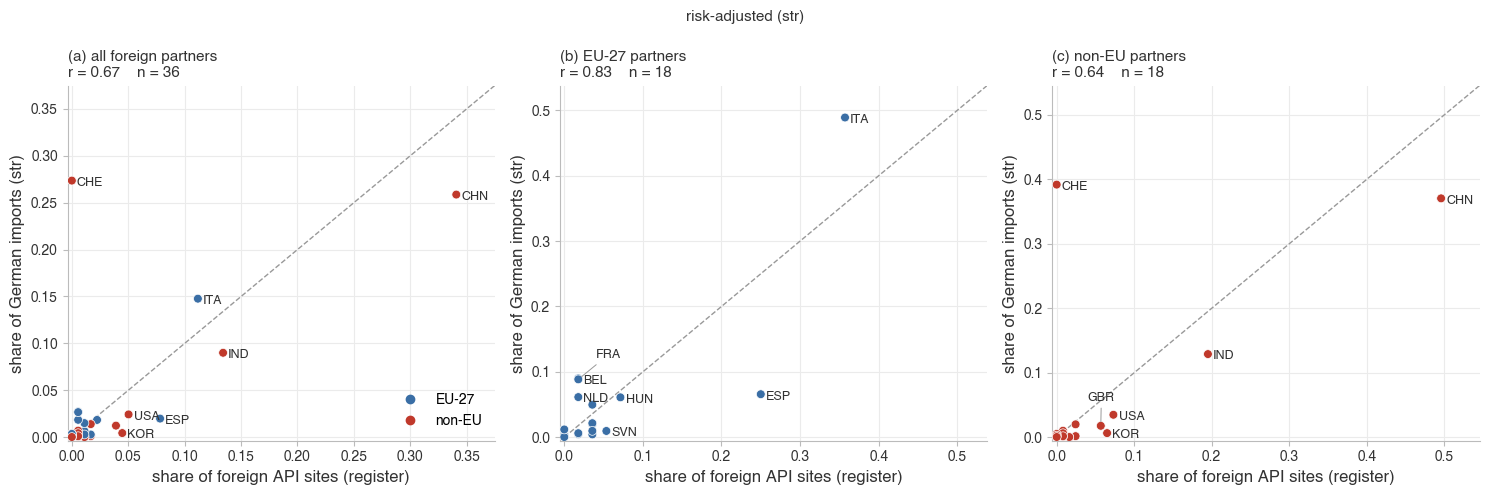

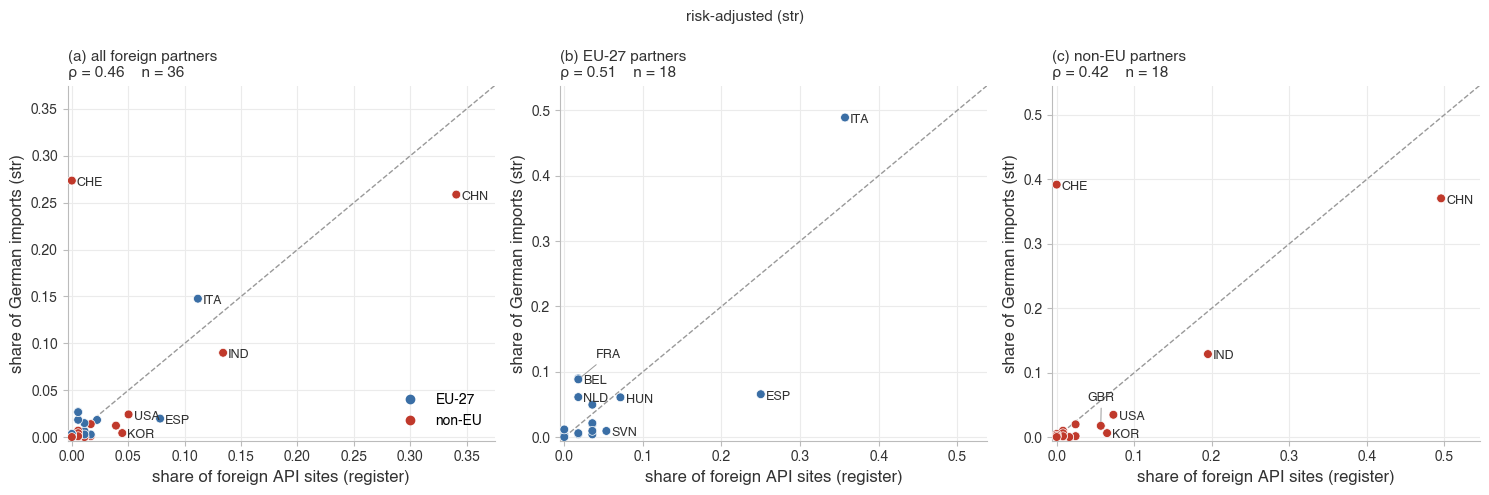

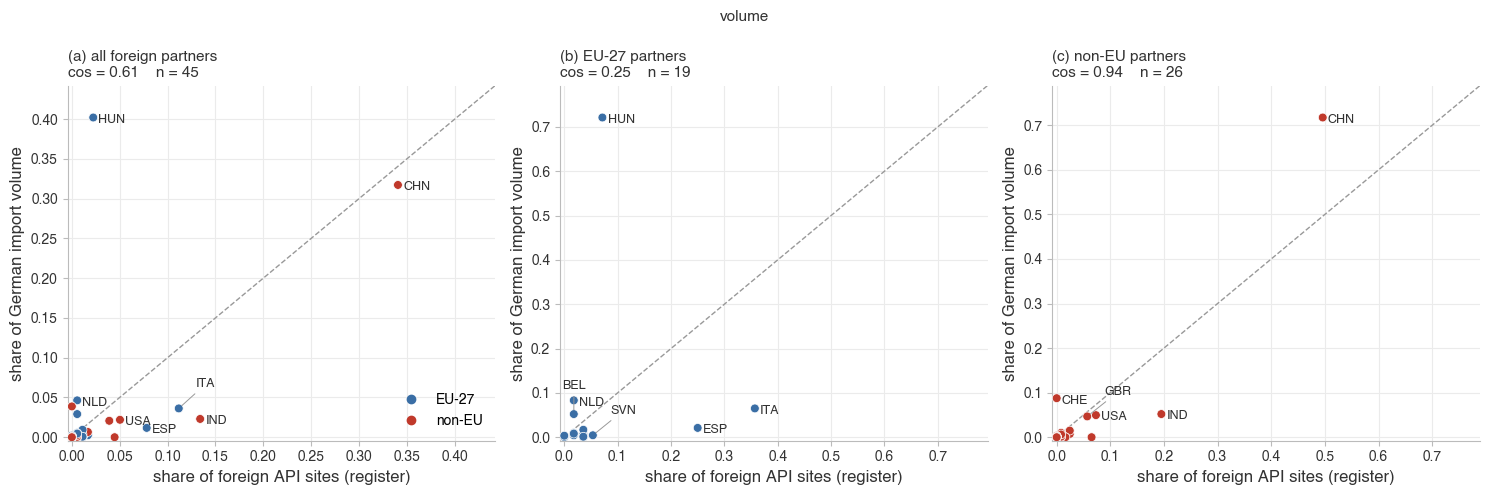

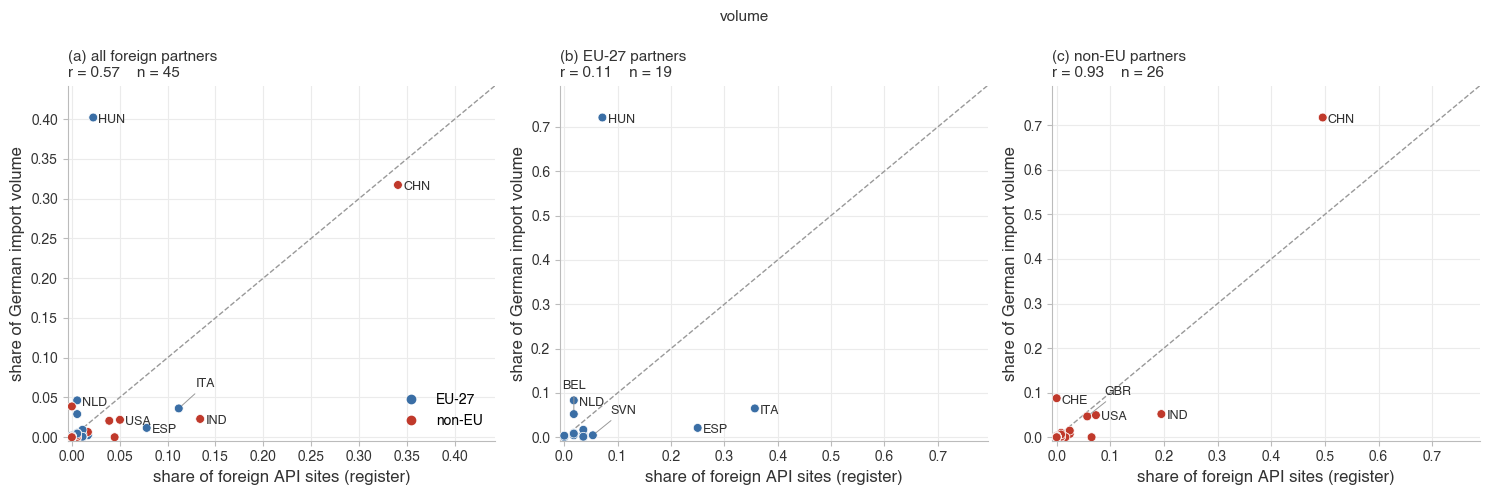

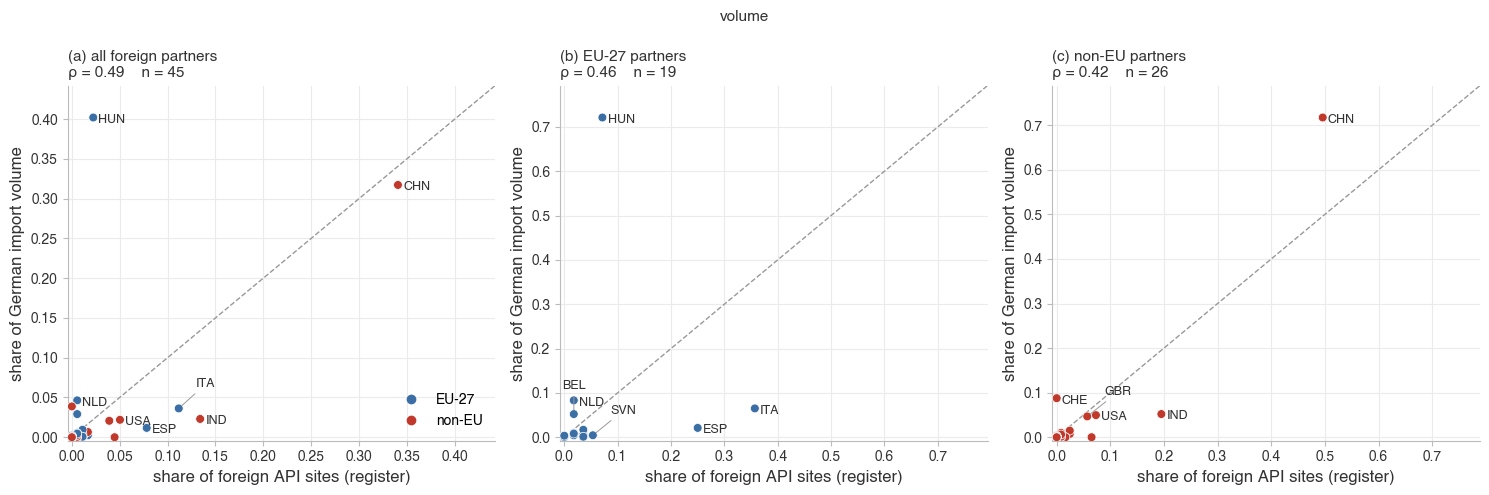

In [34]:
# --- paper style + figure: pooled over the 4 classes, one dot per partner country ---
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

G_COL = {'all foreign': ALL_C, 'EU-27': EU_C, 'non-EU': NONEU_C}

def place_labels(ax, d, lim, min_share=.04):
    # label countries above min_share, largest first: next to the dot if free, otherwise moved
    # diagonally / above / below with a thin leader line; skipped if every spot overlaps an earlier label
    placed = []
    pts = d[d.max(axis=1) > min_share]
    for c in pts.max(axis=1).sort_values(ascending=False).index:
        fx, fy = [(v + .01 * lim) / (1.01 * lim) for v in (pts.loc[c, 'register'], pts.loc[c, 'trade'])]
        w, h = .017 * len(c) + .01, .045
        spots = [(fx + .012, fy - .015, False), (fx + .04, fy + .06, True), (fx + .04, fy - .1, True),
                 (fx - w / 2, fy + .07, True), (fx - w / 2, fy - .11, True), (fx - .012 - w, fy - .015, False)]
        for x0, y0, line in spots:
            x0 = max(x0, .005)                       # keep labels inside the axes
            box = (x0, y0, x0 + w, y0 + h)
            if y0 > .005 and not any(box[0] < b[2] and b[0] < box[2] and box[1] < b[3] and b[1] < box[3]
                                     for b in placed):
                placed.append(box)
                ax.annotate(c, (pts.loc[c, 'register'], pts.loc[c, 'trade']), xytext=(x0, y0),
                            textcoords='axes fraction', fontsize=9, color='#333333',
                            arrowprops=dict(arrowstyle='-', color='#999999', lw=.7, shrinkA=1, shrinkB=3) if line else None)
                break

M_LAB = {'cosine': 'cosine similarity', 'pearson': 'Pearson r', 'spearman': 'Spearman ρ'}
M_SHORT = {'cosine': 'cos', 'pearson': 'r', 'spearman': 'ρ'}
Y_LAB = {'str': 'share of German imports (str)', 'volume': 'share of German import volume'}

def scatter_fig(w, m, sh=None, res=None, ylab=None, xlab='share of foreign API sites (register)',
                prefix='register_vs_trade'):
    sh, res, ylab = (shares if sh is None else sh), (rt if res is None else res), (Y_LAB if ylab is None else ylab)
    with plt.rc_context(STYLE):
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        for ax, g, tag in zip(axes, GROUPS, 'abc'):
            d = sh[w, g, 'pooled']
            r = res[(res.weight == w) & (res.group == g) & (res.cls == 'all 4 pooled')].iloc[0]
            ax.grid(True)
            ax.scatter(d.register, d.trade, s=40, c=np.where(d.index.isin(EU27_ISO), EU_C, NONEU_C),
                       edgecolor='white', linewidth=.5, zorder=3)
            lim = max(d.register.max(), d.trade.max()) * 1.1
            ax.plot([0, lim], [0, lim], ls='--', color='#999999', lw=1)
            ax.set_xlim(-.01 * lim, lim); ax.set_ylim(-.01 * lim, lim)
            place_labels(ax, d, lim)
            ax.set_xlabel(xlab)
            ax.set_ylabel(ylab[w])
            ax.set_title(f'({tag}) {g} partners\n{M_SHORT[m]} = {r[m]:.2f}    n = {r.n}',
                         loc='left', fontsize=11, color='#333333')
        axes[0].legend(handles=[Line2D([], [], ls='', marker='o', color=EU_C, label='EU-27'),
                                Line2D([], [], ls='', marker='o', color=NONEU_C, label='non-EU')],
                       loc='lower right', fontsize=10)
        plt.tight_layout(rect=(0, 0, 1, .93))
        fig.suptitle(W_LAB[w], **SUB)
        fig.savefig(FIG / f'{prefix}_scatter_{w}_{m}.png', dpi=200, bbox_inches='tight')
        plt.show()

for w in WEIGHTS:
    for m in MEASURES:
        scatter_fig(w, m)

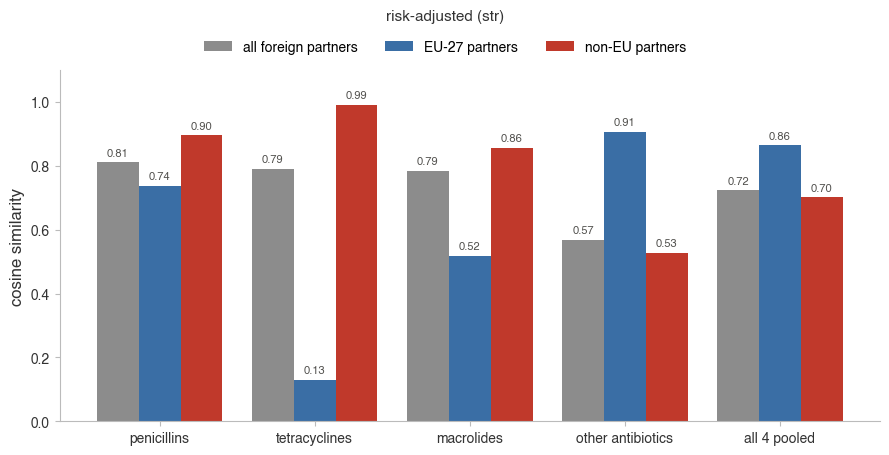

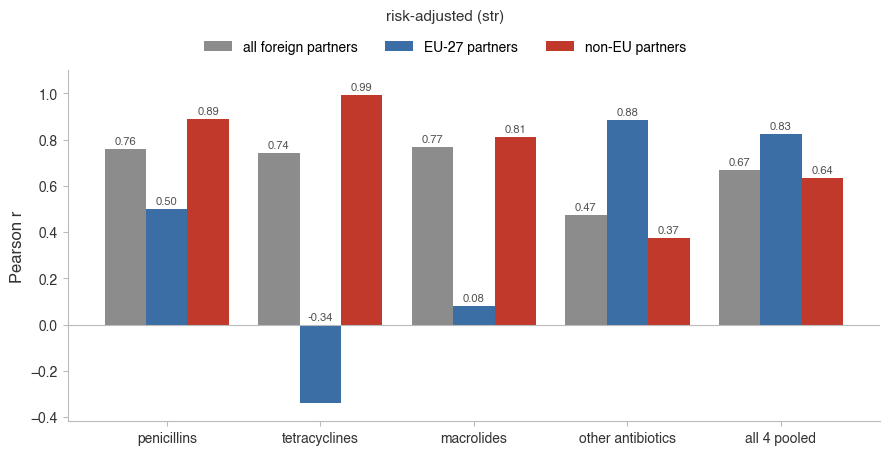

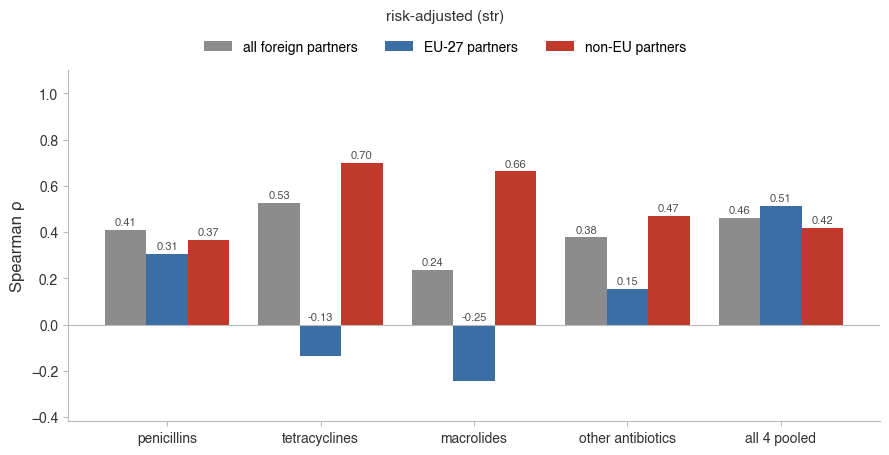

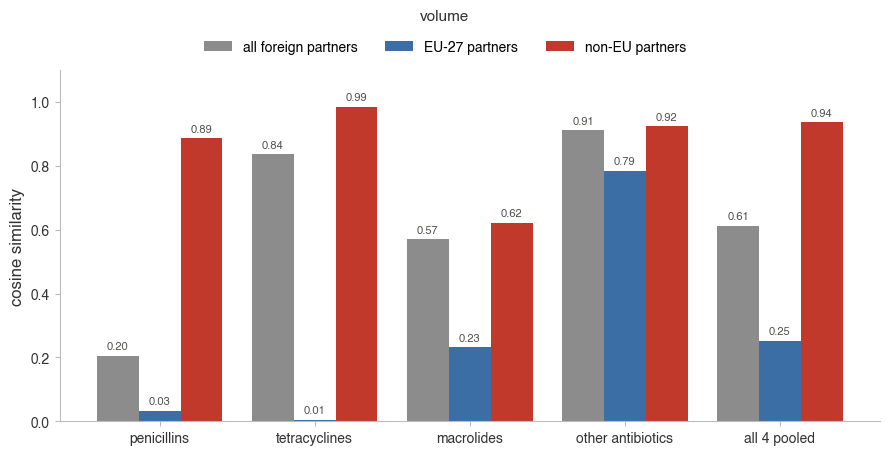

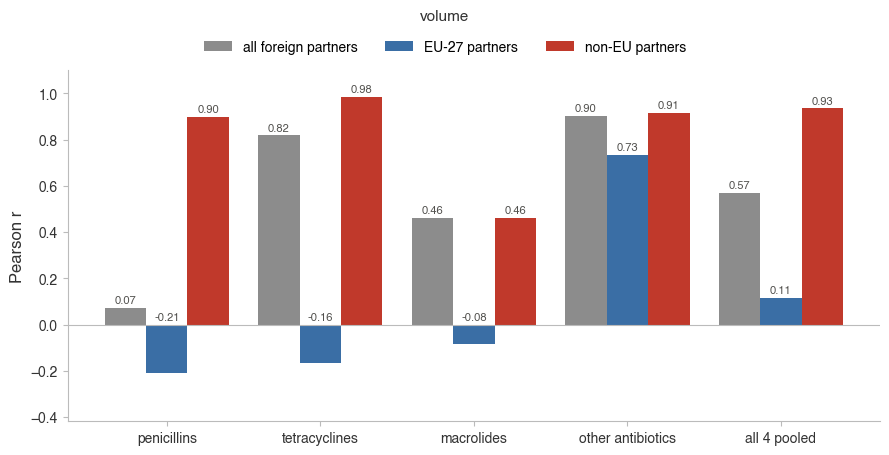

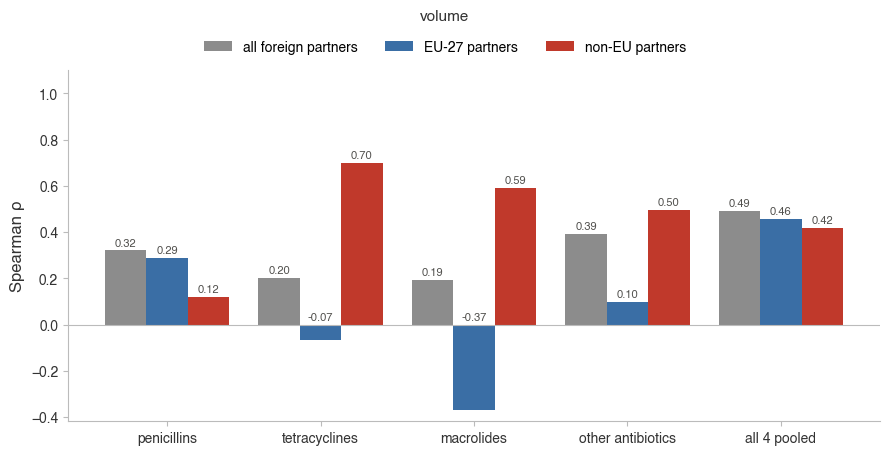

In [35]:
# --- figure: cosine, Pearson r or Spearman rho per class, for the three partner groups ---
def bars_fig(w, m, res=None, prefix='register_vs_trade'):
    res = rt if res is None else res
    with plt.rc_context(STYLE):
        fig, ax = plt.subplots(figsize=(9, 4.6))
        x, bw = np.arange(len(CLASSES)), 0.27
        for k, g in enumerate(GROUPS):
            v = res[(res.weight == w) & (res.group == g)].set_index('cls').reindex(list(CLASSES.values()))[m]
            xs = x + (k - 1) * bw
            ax.bar(xs, v.fillna(0), bw, color=G_COL[g], label=f'{g} partners')
            for xi, vi in zip(xs, v):
                ax.text(xi, max(vi, 0) + .02 if pd.notna(vi) else .02, f'{vi:.2f}' if pd.notna(vi) else 'n/a',
                        ha='center', fontsize=8, color='#52514e')
        ax.set_xticks(x); ax.set_xticklabels(list(CLASSES.values()))
        ax.set_ylabel(M_LAB[m])
        if m == 'cosine':
            ax.set_ylim(0, 1.1)                                    # cosine of shares is always in [0, 1]
        else:
            ax.axhline(0, color='#bbbbbb', lw=.8)
            ax.set_ylim(min(-.1, res[['pearson', 'spearman']].min().min() - .05), 1.1)
        plt.tight_layout(rect=(0, 0, 1, .88))
        fig.legend(*ax.get_legend_handles_labels(), loc='upper center', bbox_to_anchor=(.5, .94), ncol=3, fontsize=10)
        fig.suptitle(W_LAB[w], **SUB)
        fig.savefig(FIG / f'{prefix}_bars_{w}_{m}.png', dpi=200, bbox_inches='tight')
        plt.show()

for w in WEIGHTS:
    for m in MEASURES:
        bars_fig(w, m)

## Reading

- **Non-EU partners:** by volume the register and trade match closely (pooled r = 0.93) - China, then
  India, lead both. By `str` the match is weaker (r = 0.64) because Switzerland carries ~39% of Germany's
  non-EU `str` but has no registered API site (hub or products outside the critical list).
- **EU-27 partners:** by `str` they match (r = 0.83; Italy leads both). By volume they do not (r = 0.11)
  because Hungary is ~72% of Germany's EU-partner volume - ~1,000 t of cheap penicillin (~7 USD/kg,
  likely intermediates or veterinary) with no registered Hungarian penicillin site.
- **Caveat:** Pearson r is driven by the largest point in each panel (China outside the EU, Italy inside).
  The per-class EU-27 values rest on only 7-12 countries.
- **Spearman ρ (ranks, every country counts equally):** pooled ρ is 0.42-0.51 in every group
  (risk-adjusted 0.46 / 0.51 / 0.42, volume 0.49 / 0.46 / 0.42 for all / EU-27 / non-EU; p < 0.05 except
  non-EU risk-adjusted, p = 0.09). So without the outlier effect, register and trade agree **moderately**:
  the near-perfect non-EU volume cosine (0.94) comes mostly from China.

# 7. CEP vs trade - EU-27 (cosine similarity and correlation)

Same comparison as the German section, with the **EDQM Certificate of Suitability (CEP)** database as
the register and the **EU-27 bloc** as the importer (CEP is an EU-wide certification).

- **register share** - share of CEP holders located in country *c*: valid CEPs only, unique holder x
  country, per antibiotic class (`Data/CEP/cep_antibiotics_clean.csv`, classes mapped to the 4 HS-6 lines),
- **trade share** - share of the EU-27's antibiotic imports (sum over the 27 importers) that come from *c*,
  as **`str`** (each importer's `str` scaled by its import value in that class, then summed) or **volume**,
- partner groups: **all** partners, **EU-27** partners (= trade between member states) and **non-EU** partners.

Caveats: a CEP means a holder is *certified* to supply the EU, not that it does or how much; the country
is the holder's address, which can be a headquarters or trading company rather than the plant.

In [36]:
# --- CEP register vector and EU-27 trade vectors ---
cep = pd.read_csv(DATA / 'cep_antibiotics_clean.csv', dtype={'hs': str})
cep = cep[cep.is_valid & cep.iso3.notna() & cep.hs.isin(HS4)]
cep_sites = {hs: g.drop_duplicates(['holder', 'iso3']).iso3.value_counts() for hs, g in cep.groupby('hs')}
cep_sites['pooled'] = cep.drop_duplicates(['holder', 'iso3']).iso3.value_counts()
print(f"{len(cep)} valid CEPs, {int(cep_sites['pooled'].sum())} unique holders in {len(cep_sites['pooled'])} countries")

# EU-27 imports: t_eu (raw BACI) and st_eu (str scaled by each importer's import value), both built in Setup

def trade_vec_eu(hs, weight):
    classes = HS4 if hs == 'pooled' else [hs]
    if weight == 'str':
        return st_eu[st_eu.hs_code.isin(classes)].groupby('exporter').str_flow.sum()
    return t_eu[t_eu.hs.isin(classes)].groupby('exporter_iso3').quantity_tonnes.sum()

pd.DataFrame(cep_sites).fillna(0).astype(int).sort_values('pooled', ascending=False).head(10)

389 valid CEPs, 139 unique holders in 21 countries


,294110,294130,294150,294190,pooled
iso3,,,,,
CHN,15,16,13,43,78
IND,1,4,8,9,19
ITA,4,2,1,2,7
KOR,1,1,0,6,7
ESP,2,1,1,3,6
PRT,0,3,0,0,3
USA,0,0,2,1,3
MAC,0,2,0,0,2
NLD,1,1,1,2,2


In [37]:
# --- cosine similarity, Pearson r and Spearman rho, CEP vs EU-27 imports ---
def compare_vecs(reg, trd, group):
    both = pd.concat({'register': reg, 'trade': trd}, axis=1).fillna(0)
    if group == 'EU-27':  both = both[both.index.isin(EU27_ISO)]
    if group == 'non-EU': both = both[~both.index.isin(EU27_ISO)]
    both = both[(both > 0).any(axis=1)]
    if len(both) < MIN_N or (both.sum() == 0).any():
        return dict(cosine=np.nan, pearson=np.nan, p=np.nan, spearman=np.nan, p_s=np.nan, n=len(both)), both
    both = both / both.sum()                                   # shares within the group
    a, b = both.register.values, both.trade.values
    r, p = pearsonr(a, b)
    rho, p_s = spearmanr(a, b)
    return dict(cosine=a @ b / (np.linalg.norm(a) * np.linalg.norm(b)), pearson=r, p=p,
                spearman=rho, p_s=p_s, n=len(both)), both

rows, cep_shares = [], {}
for w in WEIGHTS:
    for g in GROUPS:
        for hs, name in CLASSES.items():
            res, both = compare_vecs(cep_sites.get(hs, pd.Series(dtype=float)), trade_vec_eu(hs, w), g)
            rows.append(dict(weight=w, group=g, cls=name, **res))
            cep_shares[w, g, hs] = both
cep_rt = pd.DataFrame(rows)
cep_rt.pivot_table(index=['weight', 'group'], columns='cls', values=['cosine', 'pearson', 'spearman', 'n'],
                   sort=False, dropna=False).round(2)

cosine                                             \
cls                penicillins tetracyclines macrolides other antibiotics   
weight group                                                                
str    all foreign        0.80          0.96       0.99              0.75   
       EU-27              0.68          0.80       0.70              0.56   
       non-EU             0.89          0.97       0.99              0.80   
volume all foreign        0.63          0.94       0.89              0.94   
       EU-27              0.52          0.29       0.60              0.69   
       non-EU             0.98          0.96       0.89              0.98   

                                    pearson                           \
cls                all 4 pooled penicillins tetracyclines macrolides   
weight group                                                           
str    all foreign         0.87        0.78          0.95       0.99   
       EU-27               0.81        0.60          0.70       0.58   
       non-EU              0.92        0.88          0.97       0.99   
volume all foreign         0.87        0.61          0.93       0.88   
       EU-27               0.73        0.44          0.13       0.50   
       non-EU              0.98        0.98          0.96       0.88   

                                                     spearman                \
cls                other antibiotics all 4 pooled penicillins tetracyclines   
weight group                                                                  
str    all foreign              0.73         0.87        0.54          0.71   
       EU-27                    0.40         0.74        0.69          0.71   
       non-EU                   0.78         0.91        0.44          0.74   
volume all foreign              0.94         0.87        0.43          0.65   
       EU-27                    0.58         0.67        0.61          0.56   
       non-EU                   0.98         0.98        0.29          0.75   

                                                                       n  \
cls                macrolides other antibiotics all 4 pooled penicillins   
weight group                                                               
str    all foreign       0.59              0.53         0.69        36.0   
       EU-27             0.54              0.45         0.55        17.0   
       non-EU            0.68              0.63         0.78        19.0   
volume all foreign       0.61              0.55         0.62        80.0   
       EU-27             0.50              0.44         0.61        23.0   
       non-EU            0.74              0.55         0.58        57.0   

                                                                            
cls                tetracyclines macrolides other antibiotics all 4 pooled  
weight group                                                                
str    all foreign          28.0       24.0              45.0         56.0  
       EU-27                14.0       13.0              25.0         25.0  
       non-EU               14.0       11.0              20.0         31.0  
volume all foreign          36.0       32.0              71.0        104.0  
       EU-27                20.0       18.0              27.0         27.0  
       non-EU               16.0       14.0              44.0         77.0

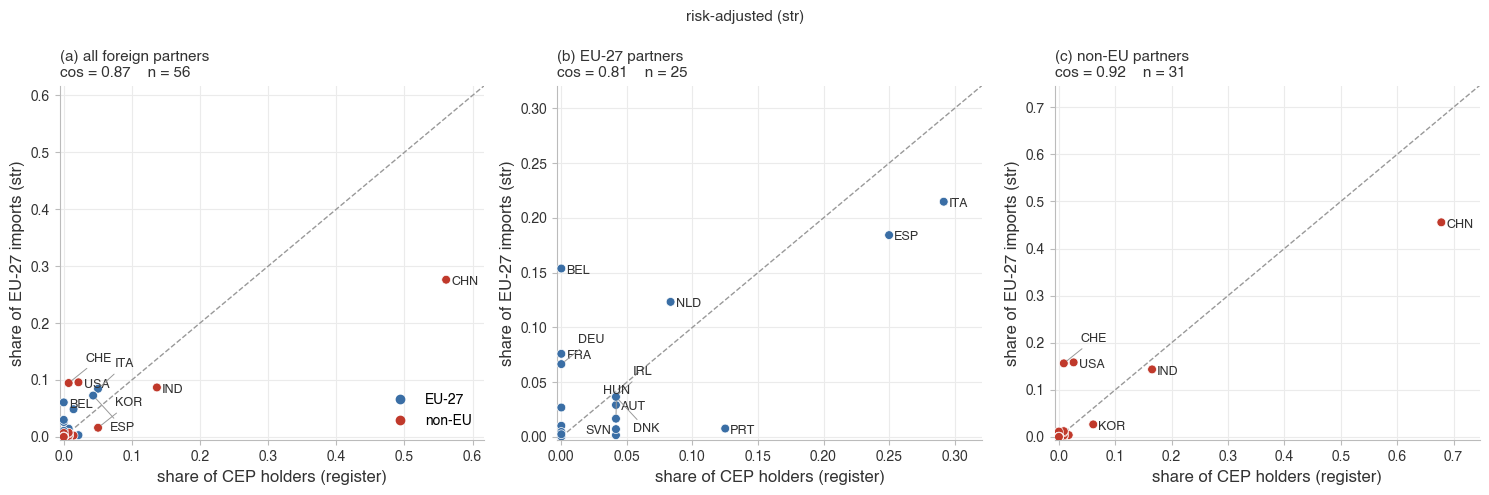

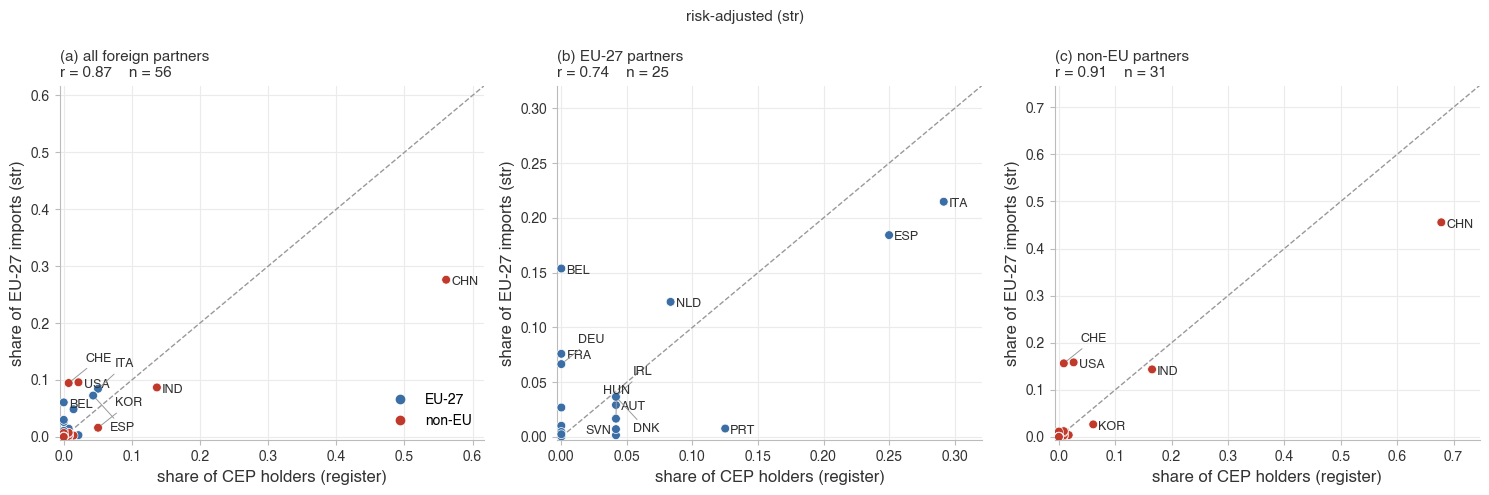

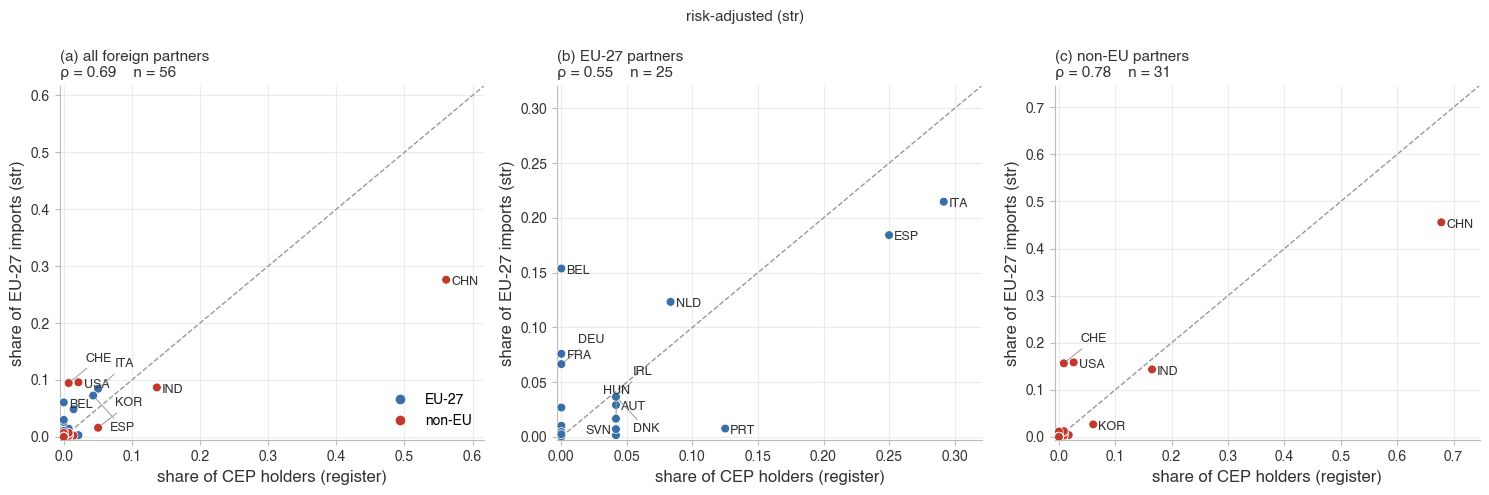

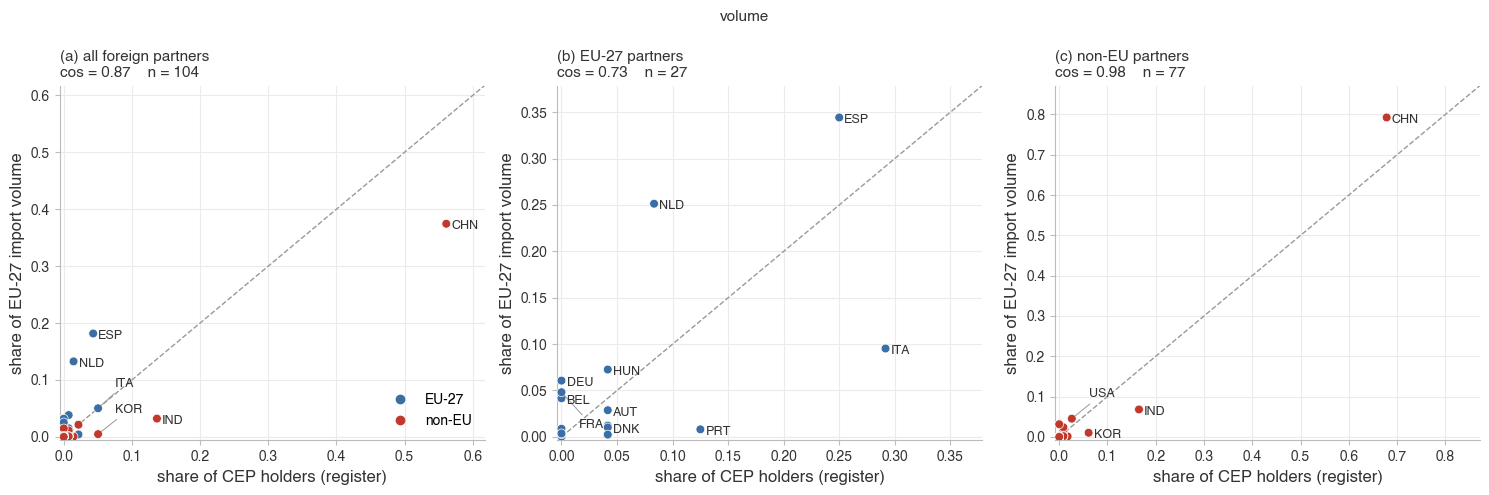

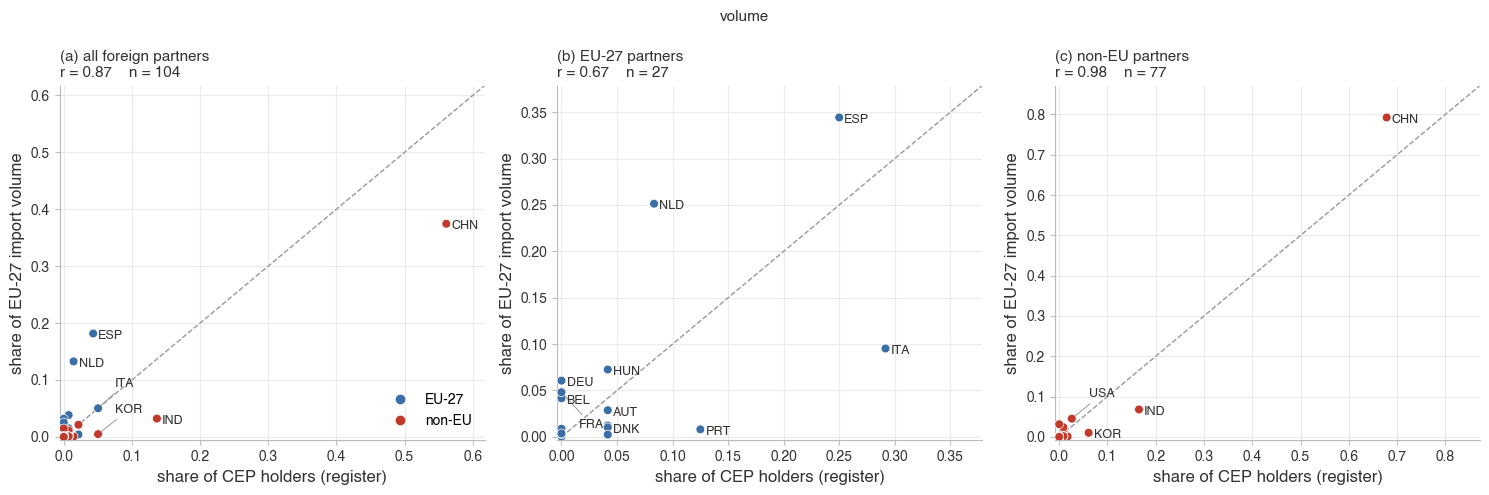

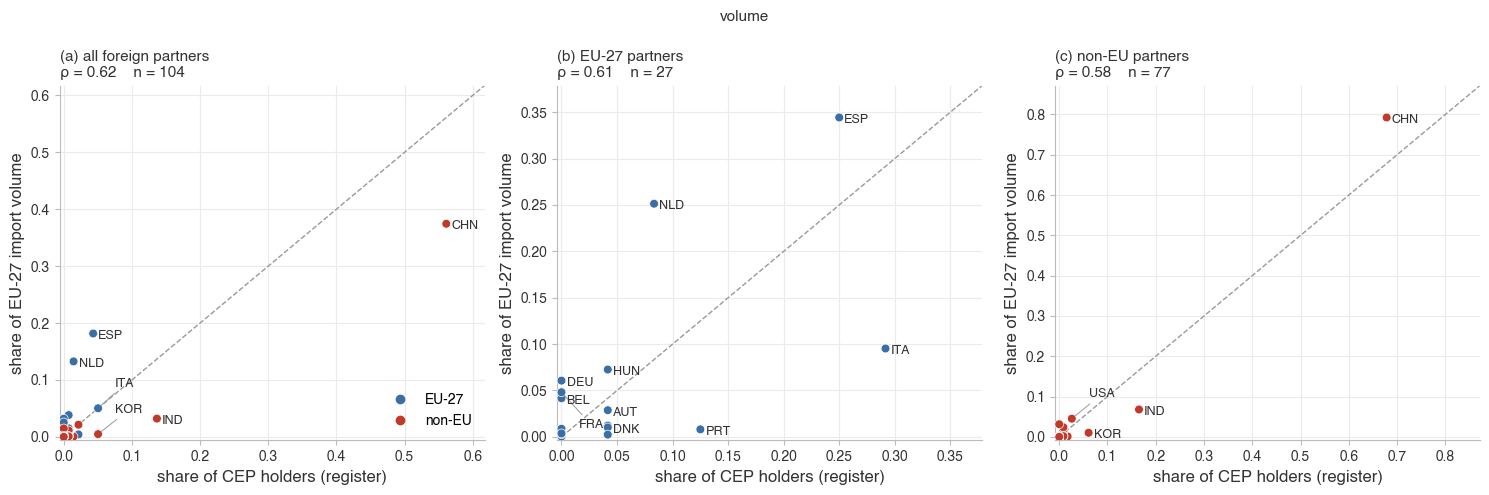

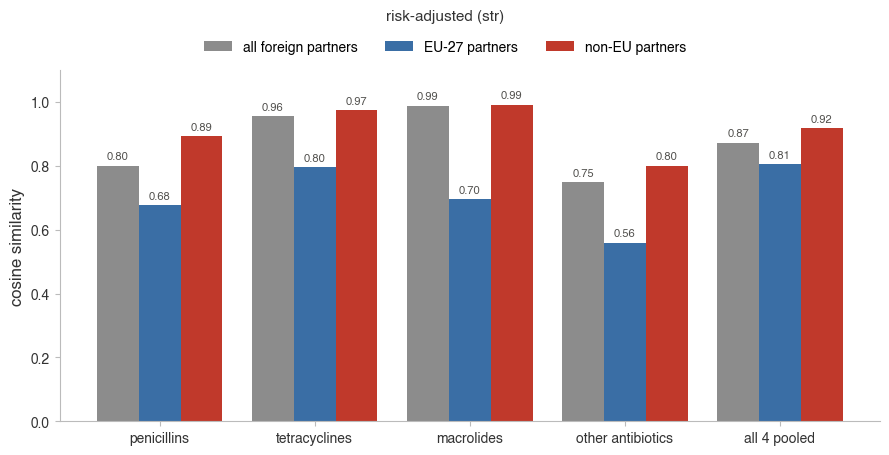

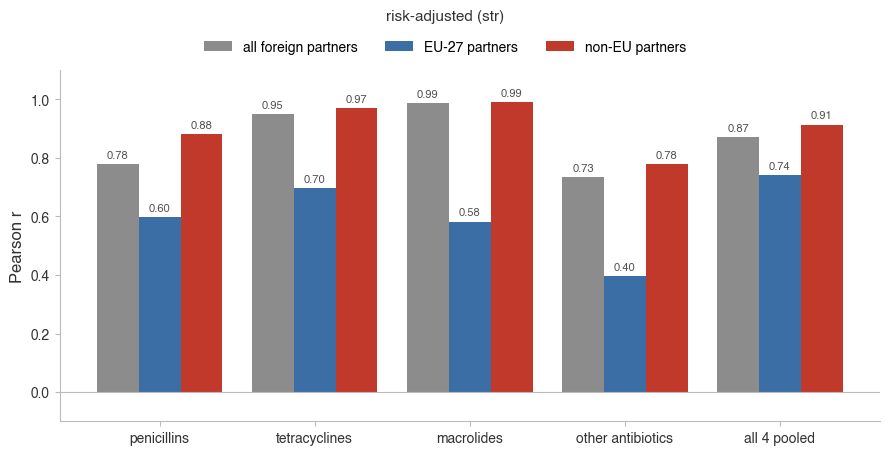

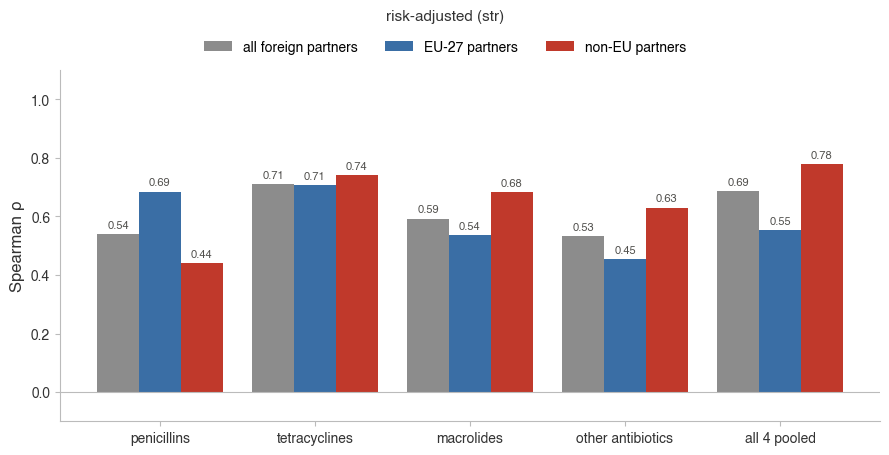

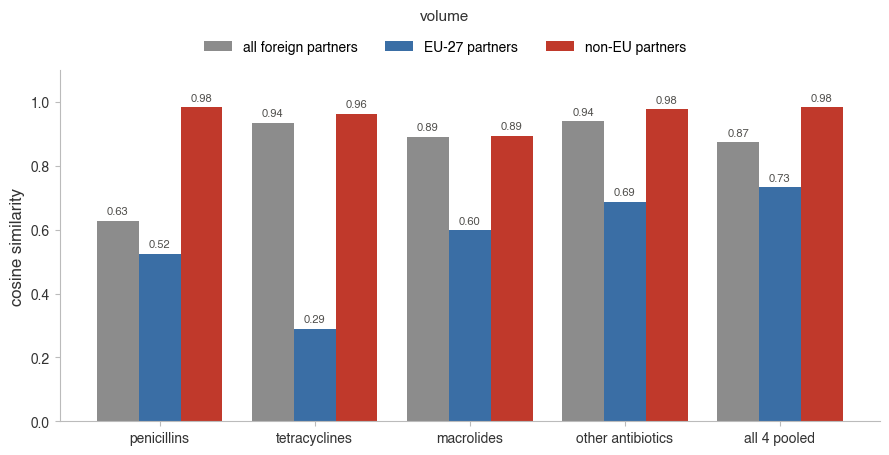

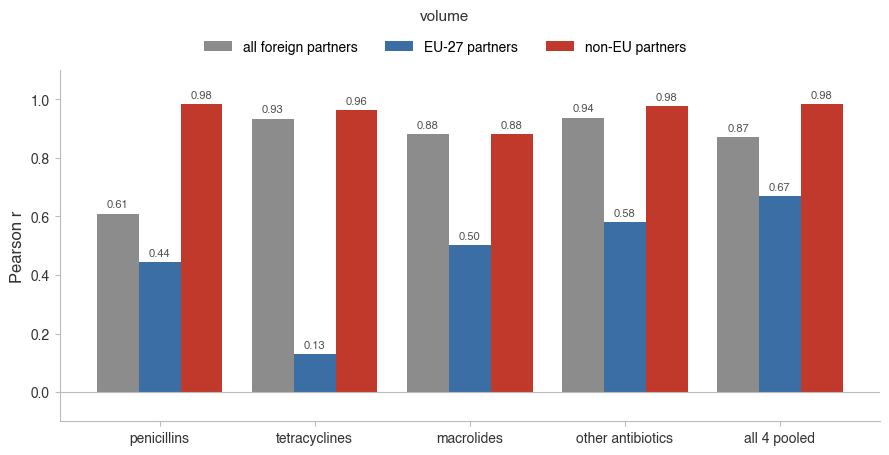

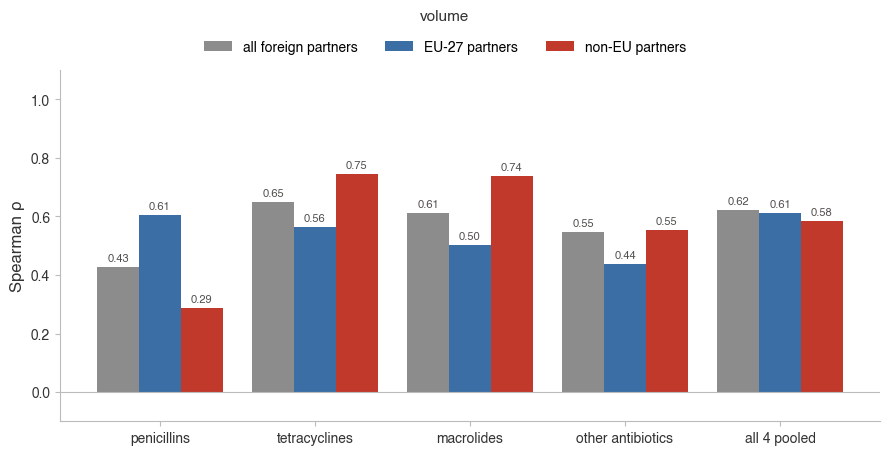

In [38]:
# --- figures: same layout and style as the German section ---
CEP_Y_LAB = {'str': 'share of EU-27 imports (str)', 'volume': 'share of EU-27 import volume'}
for w in WEIGHTS:
    for m in MEASURES:
        scatter_fig(w, m, sh=cep_shares, res=cep_rt, ylab=CEP_Y_LAB,
                    xlab='share of CEP holders (register)', prefix='cep_vs_trade')
for w in WEIGHTS:
    for m in MEASURES:
        bars_fig(w, m, res=cep_rt, prefix='cep_vs_trade')

## Reading (CEP)

- **Higher agreement than the German register.** Pooled cosine 0.87 for all partners (risk-adjusted and
  volume), against 0.72 / 0.61 for BfArM vs Germany - CEP covers critical and non-critical antibiotics,
  so its population is closer to what the HS-6 lines carry.
- **Non-EU partners: near-perfect match by volume** (cosine 0.98). China holds ~68% of non-EU CEP holders
  and ~79% of the EU's non-EU import volume. Risk-adjusted it is 0.92: Switzerland and the USA carry
  ~16% of the non-EU `str` each while holding very few CEPs.
- **EU-27 partners (trade between member states): lower** (0.81 risk-adjusted, 0.73 volume). Italy and
  Spain match; Belgium, France, Germany and the Netherlands export much more to other member states than
  their CEP count suggests - distribution / re-export hubs rather than API makers.
- **Caveats:** as in the German section, Pearson r is driven by the largest point (China). A CEP shows
  eligibility to supply, not supply, and is located at the holder's address.
- **Spearman ρ:** pooled ρ is 0.55-0.78 (risk-adjusted 0.69 / 0.55 / 0.78, volume 0.62 / 0.61 / 0.59 for
  all / EU-27 / non-EU; all p < 0.01) - lower than cosine, but clearly higher than for the German register,
  so the better CEP match is not only a China effect.

## 7b. CEP vs trade - non-EU partners with and without a CEP holder (Supplementary)

Same data as panel (c) of `cep_vs_trade_scatter_{volume,str}_spearman.png`: non-EU partners of the EU-27, the 4
antibiotic lines pooled, shares computed within the non-EU group. Each partner country is split by whether it has at
least one valid CEP holder. Uses `cep_shares`, `cep_sites`, `t_eu` and `st_eu` from the CEP section above; no figures
are saved.

In [39]:
# --- non-EU partners with vs without a CEP holder: share of EU-27 imports (same shares as panel c) ---
split_rows = []
for w in WEIGHTS:
    d = cep_shares[w, 'non-EU', 'pooled']                      # shares within the non-EU group
    has = d.register > 0
    for label, m in [('with CEP holders', has), ('without CEP holders', ~has)]:
        g = d[m].trade
        split_rows.append(dict(weight=w, group=label, countries=int(m.sum()), import_share=g.sum(),
                               median_country_share=g.median(), largest=g.idxmax(), largest_share=g.max()))
    print(f'{w}: countries with CEP holders but no imports to the EU-27:', int((d.trade[has] == 0).sum()))
cep_split = pd.DataFrame(split_rows)
cep_split.round(3)

str: countries with CEP holders but no imports to the EU-27: 0
volume: countries with CEP holders but no imports to the EU-27: 0


,weight,group,countries,import_share,median_country_share,largest,largest_share
0,str,with CEP holders,11,0.978,0.012,CHN,0.456
1,str,without CEP holders,20,0.022,0.000,SGP,0.011
2,volume,with CEP holders,11,0.963,0.010,CHN,0.792
3,volume,without CEP holders,66,0.037,0.000,SGP,0.031


In [40]:
# --- SI table: each non-EU country with CEP holders, then both groups pooled ---
vol, stv = cep_shares['volume', 'non-EU', 'pooled'], cep_shares['str', 'non-EU', 'pooled']
cep_c = vol.index[vol.register > 0]
si = pd.DataFrame({'cep_holders': cep_sites['pooled'].reindex(cep_c),
                   'cep_share': vol.register[cep_c],
                   'volume_share': vol.trade[cep_c],
                   'str_share': stv.trade.reindex(cep_c).fillna(0)}).sort_values(['cep_holders', 'volume_share'],
                                                                                 ascending=False)
si.loc['with CEP holders'] = si.sum()
si.loc['without CEP holders'] = [0, 0, vol.trade[vol.register == 0].sum(), stv.trade[stv.register == 0].sum()]
si['cep_holders'] = si.cep_holders.astype(int)
print(f'without CEP holders: {int((vol.register == 0).sum())} countries by volume, {int((stv.register == 0).sum())} by str')
si.round(3)

without CEP holders: 66 countries by volume, 20 by str


,cep_holders,cep_share,volume_share,str_share
CHN,78,0.678,0.792,0.456
IND,19,0.165,0.068,0.143
KOR,7,0.061,0.010,0.026
USA,3,0.026,0.045,0.158
MAC,2,0.017,0.001,0.004
CHE,1,0.009,0.024,0.156
GBR,1,0.009,0.015,0.007
JPN,1,0.009,0.003,0.010
BRA,1,0.009,0.002,0.012
MEX,1,0.009,0.001,0.001


In [41]:
# --- why the volume panels have more countries than the str panels ---
only_vol, only_str = vol.index.difference(stv.index), stv.index.difference(vol.index)
print(f'exporters to the EU-27: raw BACI {t_eu[t_eu.hs.isin(HS4)].exporter_iso3.nunique()}, '
      f'str file {st_eu.exporter.nunique()}')
print(f'non-EU countries only in the volume panel: {len(only_vol)}, '
      f'with a CEP holder: {int((vol.register[only_vol] > 0).sum())}, '
      f'together {vol.trade[only_vol].sum():.2%} of non-EU import volume (largest {vol.trade[only_vol].max():.2%})')
print(f'non-EU countries only in the str panel: {len(only_str)} ({", ".join(only_str)})')

exporters to the EU-27: raw BACI 108, str file 56
non-EU countries only in the volume panel: 47, with a CEP holder: 0, together 0.05% of non-EU import volume (largest 0.02%)
non-EU countries only in the str panel: 1 (EGY)


In [42]:
# --- LaTeX version of the SI table (volume), ready to paste ---
pct = lambda x: f'{100 * x:.1f}\\%'
no_cep = vol.trade[vol.register == 0]
label = {'with CEP holders': f'With CEP holders ({len(cep_c)} countries)',
         'without CEP holders': f'Without CEP holders ({len(no_cep)} countries)'}
body = [f'{label.get(c, c)} & {int(r.cep_holders)} & {pct(r.cep_share)} & {pct(r.volume_share)} \\\\'
        for c, r in si.iterrows()]
body.insert(len(cep_c), r'\midrule')
print('\n'.join([
    r'\begin{table}[ht]', r'\centering',
    r'\caption{Non-EU partner countries of the EU-27 with at least one valid CEP holder for antibiotics '
    r'(HS 294110, 294130, 294150 and 294190 pooled): number of CEP holders, share of all non-EU CEP holders, '
    r'and share of EU-27 antibiotic import volume from non-EU partners (BACI 2024). The last row pools the '
    f'{len(no_cep)} non-EU exporters without a CEP holder; the largest of them is {no_cep.idxmax()} '
    f'({pct(no_cep.max())}). Countries are given by ISO 3166-1 alpha-3 code.}}',
    r'\label{tab:cep_split}', r'\begin{tabular}{lrrr}', r'\toprule',
    r'Country & CEP holders & Share of CEP holders & Share of import volume \\', r'\midrule',
    *body, r'\bottomrule', r'\end{tabular}', r'\end{table}']))

\begin{table}[ht]
\centering
\caption{Non-EU partner countries of the EU-27 with at least one valid CEP holder for antibiotics (HS 294110, 294130, 294150 and 294190 pooled): number of CEP holders, share of all non-EU CEP holders, and share of EU-27 antibiotic import volume from non-EU partners (BACI 2024). The last row pools the 66 non-EU exporters without a CEP holder; the largest of them is SGP (3.1\%). Countries are given by ISO 3166-1 alpha-3 code.}
\label{tab:cep_split}
\begin{tabular}{lrrr}
\toprule
Country & CEP holders & Share of CEP holders & Share of import volume \\
\midrule
CHN & 78 & 67.8\% & 79.2\% \\
IND & 19 & 16.5\% & 6.8\% \\
KOR & 7 & 6.1\% & 1.0\% \\
USA & 3 & 2.6\% & 4.5\% \\
MAC & 2 & 1.7\% & 0.1\% \\
CHE & 1 & 0.9\% & 2.4\% \\
GBR & 1 & 0.9\% & 1.5\% \\
JPN & 1 & 0.9\% & 0.3\% \\
BRA & 1 & 0.9\% & 0.2\% \\
MEX & 1 & 0.9\% & 0.1\% \\
TUR & 1 & 0.9\% & 0.1\% \\
\midrule
With CEP holders (11 countries) & 115 & 100.0\% & 96.3\% \\
Without CEP holders (66 countries) &

## Reading (CEP split)

- **Countries with CEP holders are the EU's non-EU suppliers.** The 11 non-EU countries with a CEP holder supply
  96.3% of the EU-27's non-EU import volume (97.8% by `str`), and every one of them trades with the EU.
- **Countries without a CEP trade much less.** The 66 non-EU exporters without a CEP holder supply 3.7% of the volume
  together (2.2% by `str`, 20 countries); the median country is ~0% and the largest is Singapore (3.1%).
- **Not proportional, as in the scatter.** China is 67.8% of non-EU CEP holders and 79.2% of the volume. Switzerland
  and the USA have only 1 and 3 CEP holders but 2.4% / 4.5% of the volume and ~16% of the `str` each.
- **Why the volume panels have more countries:** the `str` file lists 56 exporters to the EU-27, raw BACI 108. The 47
  non-EU countries that appear only in the volume panel hold no CEP and together carry 0.05% of non-EU import volume
  (Egypt is the one country that appears only in the `str` panel).

# 8. Exploratory: unit value (implied price) - re-export screening

`value_1000_usd / quantity_tonnes = USD per kg` (the thousands cancel: k-USD / tonne = USD/kg).

Idea: a supplier that ships at a price **close to the origin price** (China/India) is likely a
**pass-through / re-export hub**, not a real producer; a supplier with a real markup may be doing
genuine value-added processing. This is a **screening tool** - pooled over 4 codes it is noisy,
so cross-check any flag against the register before concluding.

In [43]:
# implied price per exporter (value-weighted, pooled over the 4 codes)
uv = df.groupby('exporter_name').agg(value=('value_1000_usd', 'sum'),
                                     qty=('quantity_tonnes', 'sum'))
uv['usd_per_kg'] = uv['value'] / uv['qty']
top = uv.sort_values('value', ascending=False).head(15)
top.round(2)

,value,qty,usd_per_kg
exporter_name,,,
China,4542108.87,87693.92,51.80
India,1047867.22,13215.91,79.29
Italy,920352.66,3959.76,232.43
Switzerland,837335.75,485.64,1724.18
USA,616875.79,2489.42,247.80
Spain,483306.03,9669.83,49.98
Belgium,326981.12,921.23,354.94
Netherlands,258192.15,4694.48,55.00
Denmark,178272.96,383.56,464.78


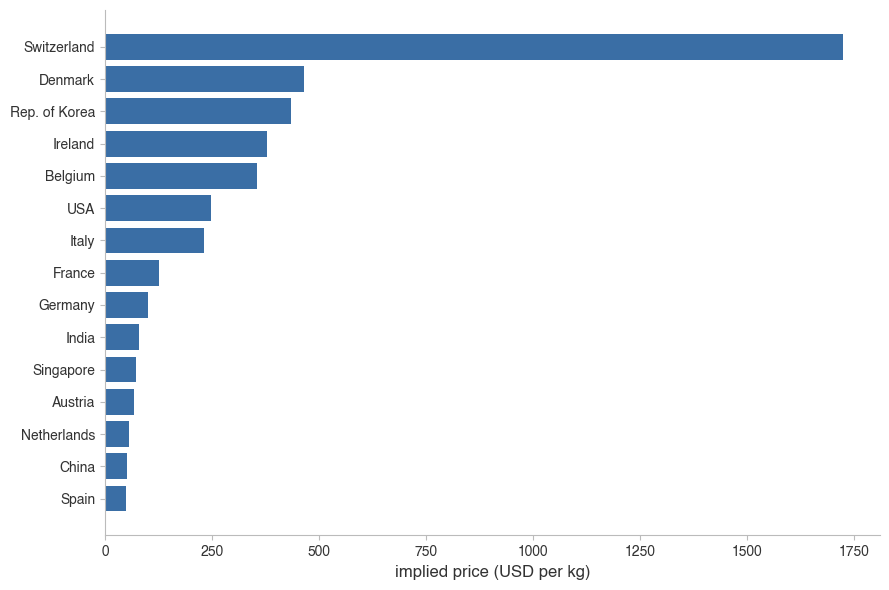

In [44]:
# --- bar chart: unit value of the top-15 suppliers by export value (exploratory, not saved) ---
t = top.sort_values('usd_per_kg')
with plt.rc_context(STYLE):
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(t.index, t['usd_per_kg'], color=EU_C)
    ax.set_xlabel('implied price (USD per kg)')
    plt.tight_layout(); plt.show()

In [45]:
# --- per HS6 code: origins vs EU hubs (per-code is cleaner than pooled) ---
watch = ['China', 'India', 'Switzerland', 'Belgium', 'Netherlands', 'Germany', 'Italy']
g = (raw[raw.exporter_name.isin(watch)]
     .groupby(['exporter_name', 'hs6_description'])
     .agg(value=('value_1000_usd', 'sum'), qty=('quantity_tonnes', 'sum')))
g['usd_per_kg'] = g['value'] / g['qty']
g['usd_per_kg'].unstack().round(1)

hs6_description,Antibiotics: erythromycin and its derivatives: salts thereof,Antibiotics: n.e.c. in heading no. 2941,Antibiotics: penicillins and their derivatives with a penicillanic acid structure: salts thereof,Antibiotics: tetracyclines and their derivatives: salts thereof
exporter_name,,,,
Belgium,14.7,423.5,122.8,70.6
China,117.5,71.2,32.9,25.2
Germany,174.1,173.2,38.7,49.9
India,140.9,132.0,42.2,94.3
Italy,438.6,228.2,181.6,824.0
Netherlands,182.2,152.0,18.8,33.0
Switzerland,264.3,1741.7,59.0,1673.5
